# Whom to Silence, Whom to Amplify: experiments

This notebook reruns every phase **from the checkpoints** in `data/processed/checkpoints/` (no refits) and redraws every figure in
`results/`, then checks the report's numbers. Runtime from checkpoints: about 5 minutes on 12 cores (measured: 293 s).

**Full refit from scratch** (deletes nothing by itself; add `--fresh` to a phase to drop its checkpoints):

| Phase | Command | Runtime from scratch |
|---|---|---|
| 1–4 | `python src/data_prep.py --check`, `features.py`, `network.py`, `drive.py` | ~3 min |
| 5 | `python src/sair.py --fresh --check` | 6–8 h |
| 5 extra | `python src/sair.py --recovery-extra` | ~1.5 h |
| 6 | `python src/ablation.py --check` | 1.5–2 h |
| 7 | `python src/control.py --fresh --check` and `--tipping` | ~3 min + ~25 min |
| 8 | `python src/targeting.py --part AB --fresh --check` | ~40 min |

Raw data must be in `data/raw/` (see `data/raw/README.md`).

In [1]:
import os, subprocess, sys, time
from IPython.display import Image, display
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
os.chdir(ROOT)
ENV = {**os.environ, 'LOKY_MAX_CPU_COUNT': '4', 'PYTHONIOENCODING': 'utf-8'}

def run(cmd, tail=12):
    t0 = time.time()
    p = subprocess.run([sys.executable] + cmd.split(), capture_output=True, text=True, env=ENV, encoding='utf-8', errors='replace')
    print('\n'.join((p.stdout + p.stderr).strip().splitlines()[-tail:]))
    print(f'--- {cmd}: exit {p.returncode}, {time.time() - t0:.0f} s')
    assert p.returncode == 0, cmd

def show(*names):
    for n in names:
        display(Image(filename=os.path.join('results', n)))
print(ROOT)

C:\Users\HP\OneDrive\Documents\sair_project


## Phase 1–4: data, features, network, drive

peak_I_h                              50.000000      6.000000               2.000000
peak_A                                48.100000     94.800000             227.000000
peak_A_h                              27.000000     14.000000               1.750000
final_C_I                           7386.000000   2831.000000             440.000000
final_C_A                            157.000000    148.000000             266.000000
max_I_drop_1bin                        0.079956      0.079956               0.020618

--- Phase 1 check ---
charliehebdo           OK  N=8,251  bins=136  max|sum frac - 1|=4.4e-16  max 1-bin I drop=8.0%  tail C_I=0.01%  tail C_A=3.82%  entries after trim I/A=3/0
sydneysiege            OK  N=3,105  bins=47  max|sum frac - 1|=4.4e-16  max 1-bin I drop=8.0%  tail C_I=0.00%  tail C_A=0.00%  entries after trim I/A=3/0
story_three_shootings  OK  N=721  bins=125  max|sum frac - 1|=2.2e-16  max 1-bin I drop=2.1%  tail C_I=0.00%  tail C_A=0.00%  entries after trim I/A=1/0
All P

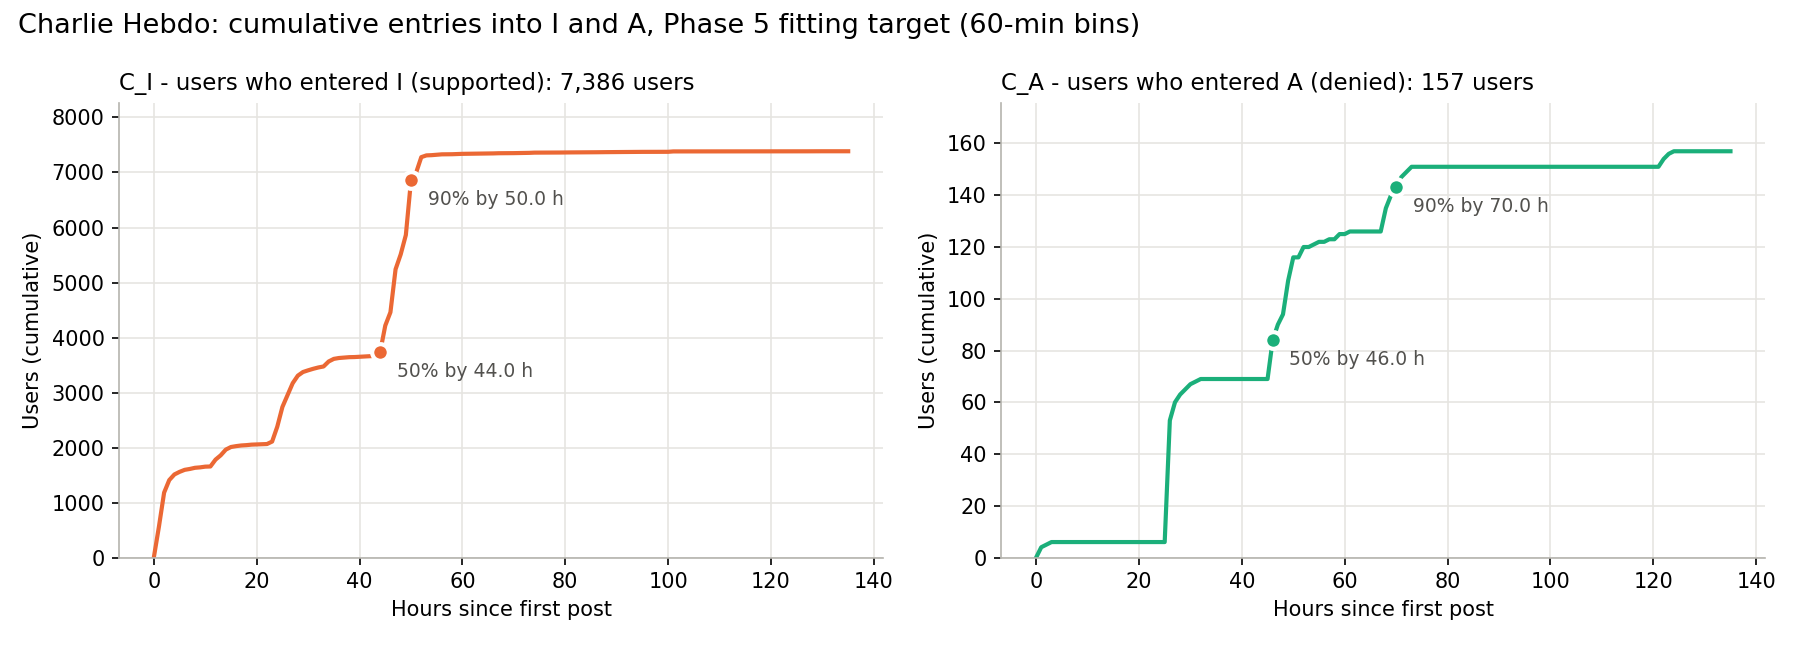

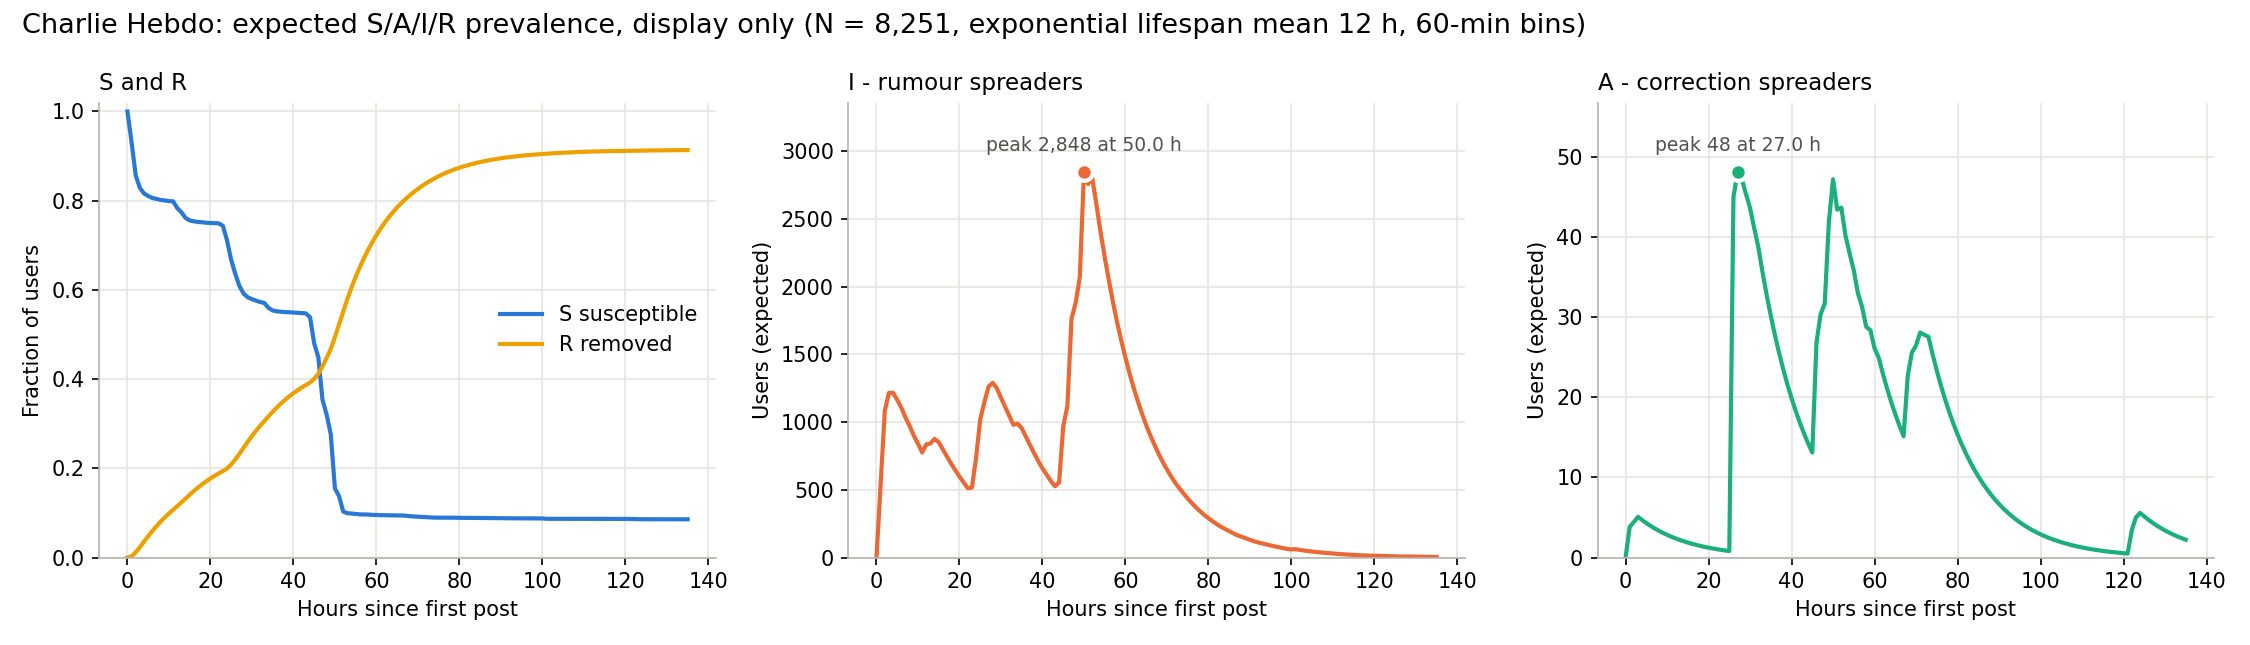

In [2]:
run('src/data_prep.py --check')
show('cumulative_curves_charliehebdo.png', 'real_curves_charliehebdo.png')

story_three_shootings   Info_match 0.4984             0.5016           False
story_three_shootings connectivity 0.3961             0.6039           False
story_three_shootings friend_power 0.7633             0.7633           False
story_three_shootings     has_text 0.4954             0.5046           False
story_three_shootings  has_emotion 0.4792             0.5208           False
story_three_shootings  has_friends 0.5256             0.5256           False

--- Phase 2 check ---
charliehebdo           OK  N=8,251  features in range, no NaN, Pop max=1  max AUC=0.641 (friend_power)
sydneysiege            OK  N=3,105  features in range, no NaN, Pop max=1  max AUC=0.542 (has_emotion)
story_three_shootings  OK  N=721  features in range, no NaN, Pop max=1  max AUC=0.763 (friend_power)
All Phase 2 checks passed.
--- src/features.py --check: exit 0, 22 s


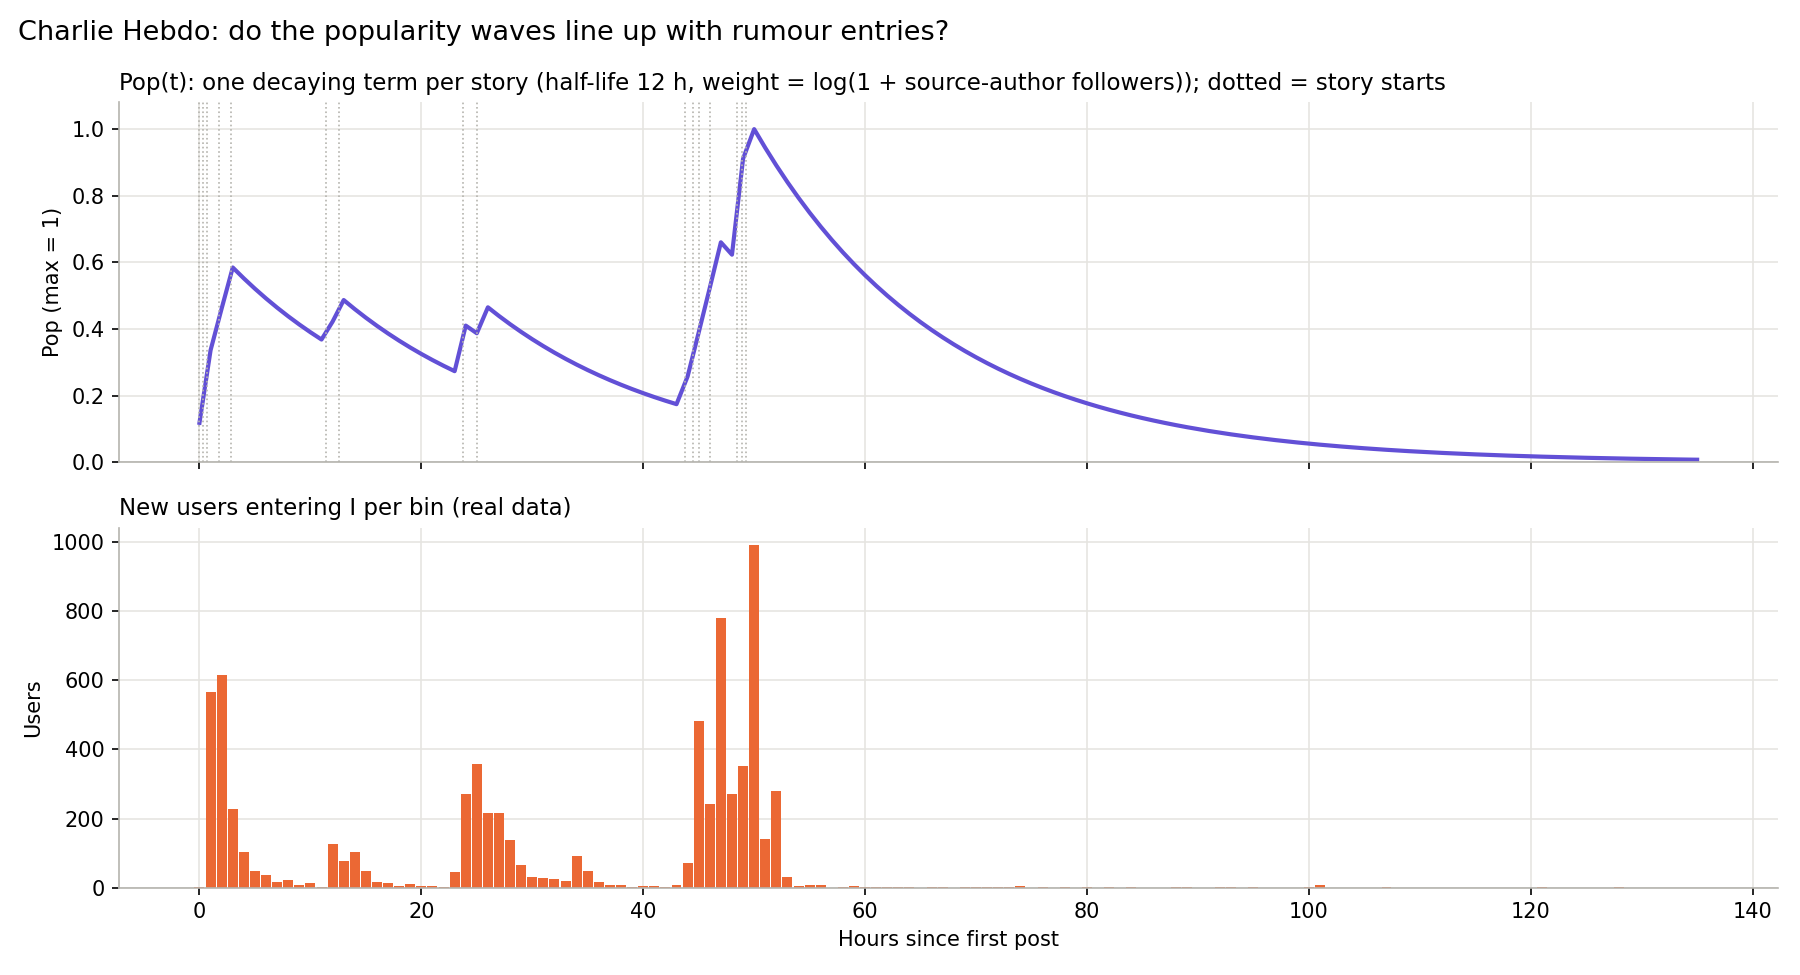

In [3]:
run('src/features.py --check')
show('pop_vs_entries_charliehebdo.png')

story_three_shootings             Gact 0.5290             0.5290           False
story_three_shootings             Gpre 0.5000             0.5000           False
story_three_shootings        Group_att 0.5000             0.5000           False
story_three_shootings      Gact_follow 0.5983             0.5983           False
story_three_shootings      Gpre_follow 0.4680             0.5320           False
story_three_shootings Group_att_follow 0.4680             0.5320           False

--- Phase 3 check ---
charliehebdo           OK  N=8,251  core=83 (1.0%)  groups=20  NMI(group, thread) profile=0.038 vs follow=0.707  r in [0.05, 0.95]  max AUC=0.611 (pr_norm)
sydneysiege            OK  N=3,105  core=32 (1.0%)  groups=20  NMI(group, thread) profile=0.035 vs follow=0.639  r in [0.05, 0.95]  max AUC=0.741 (Gpre_follow)
story_three_shootings  OK  N=721  core=8 (1.1%)  groups=20  NMI(group, thread) profile=0.013 vs follow=0.393  r in [0.05, 0.95]  max AUC=0.606 (r)
All Phase 3 checks passed.
-

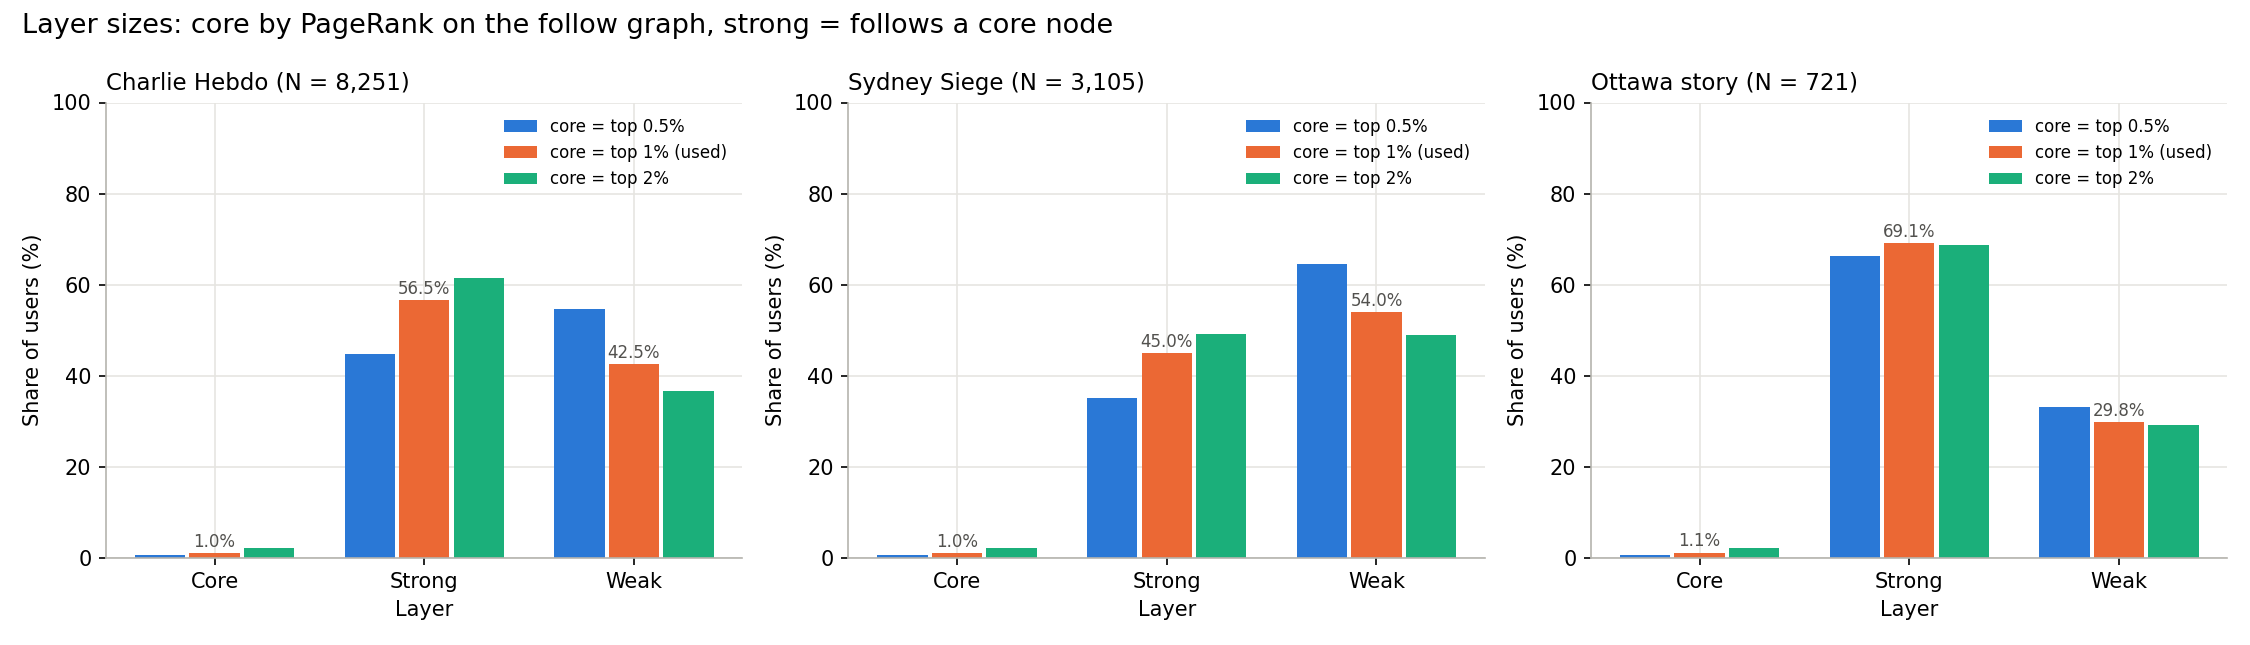

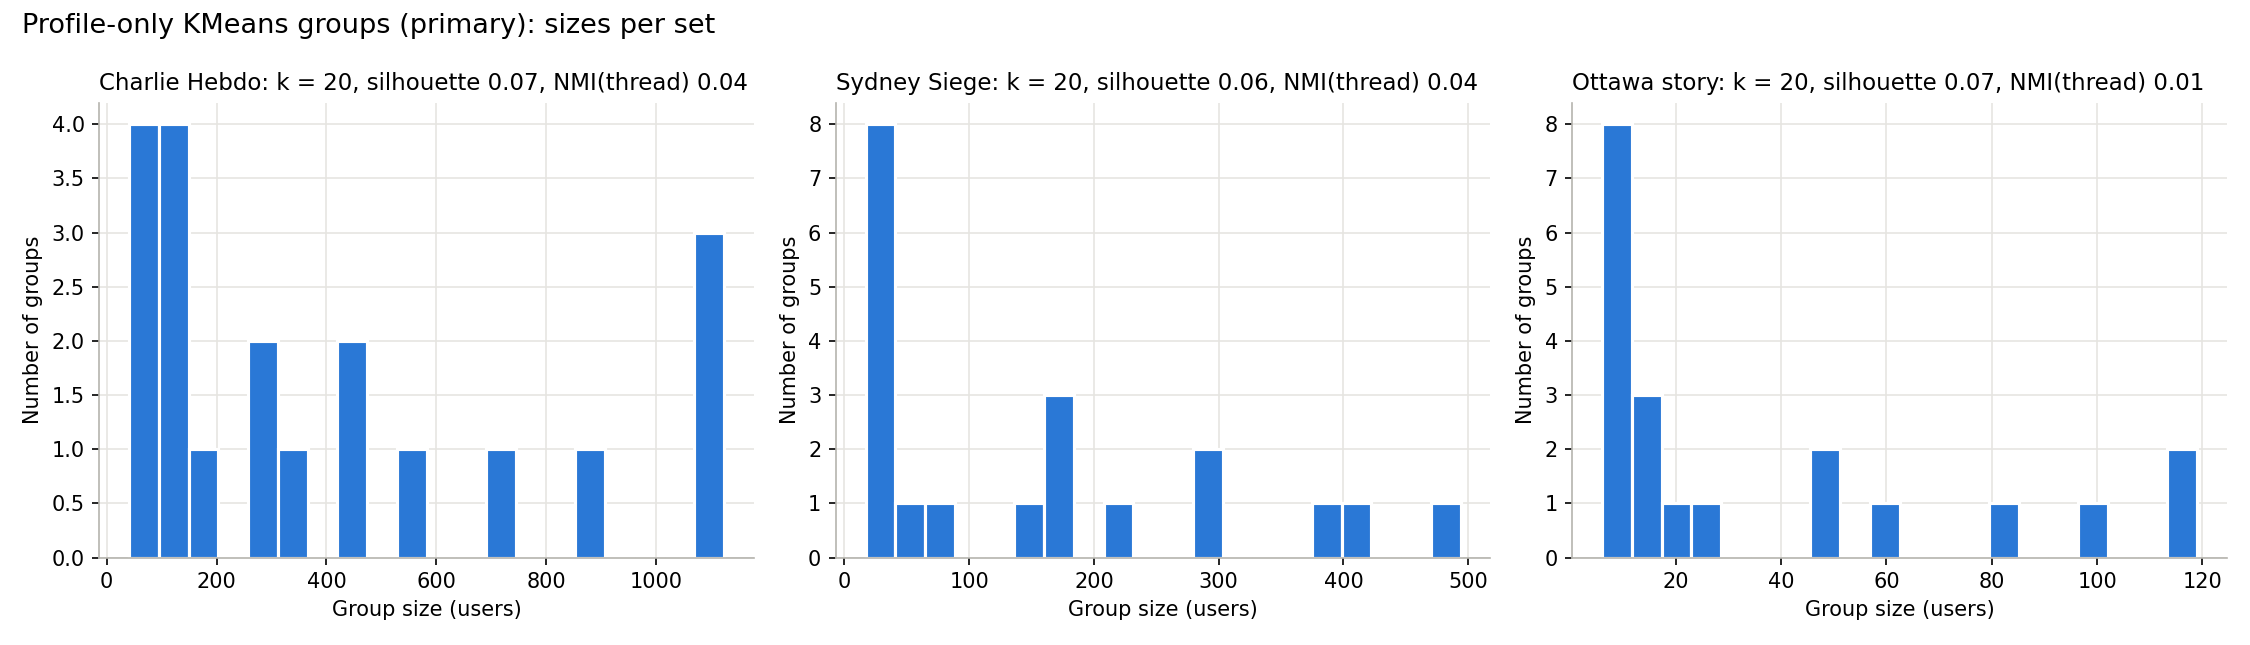

In [4]:
run('src/network.py --check')
show('phase3_layer_sizes.png', 'phase3_group_sizes.png')

=== P1 at entry: overall AUC vs pooled AUC within threads that contain both I and A ===
                  set  auc_P1_overall  threads_total  threads_with_I_and_A  users_in_those_threads  auc_P1_within_thread_pooled
         charliehebdo          0.8593             35                    12                    2284                       0.4280
          sydneysiege          0.8636             20                    14                    2069                       0.4909
story_three_shootings          0.9779              2                     2                     707                       0.4274

--- Phase 4 check ---
worked example: Mult_eff = 2, P1 = 0.8 -> Drif1 = 0.7685 (expected ~0.769)
charliehebdo           OK  N=8,251  max|Drif1+Drif2-1|=1e-16  Mult_eff in [0.00, 2.00]  CV AUC strat=0.512 thread=0.314 gap=+0.198  <-- GAP > 0.10
sydneysiege            OK  N=3,105  max|Drif1+Drif2-1|=1e-16  Mult_eff in [0.00, 2.00]  CV AUC strat=0.583 thread=0.532 gap=+0.051
story_three_shootings  O

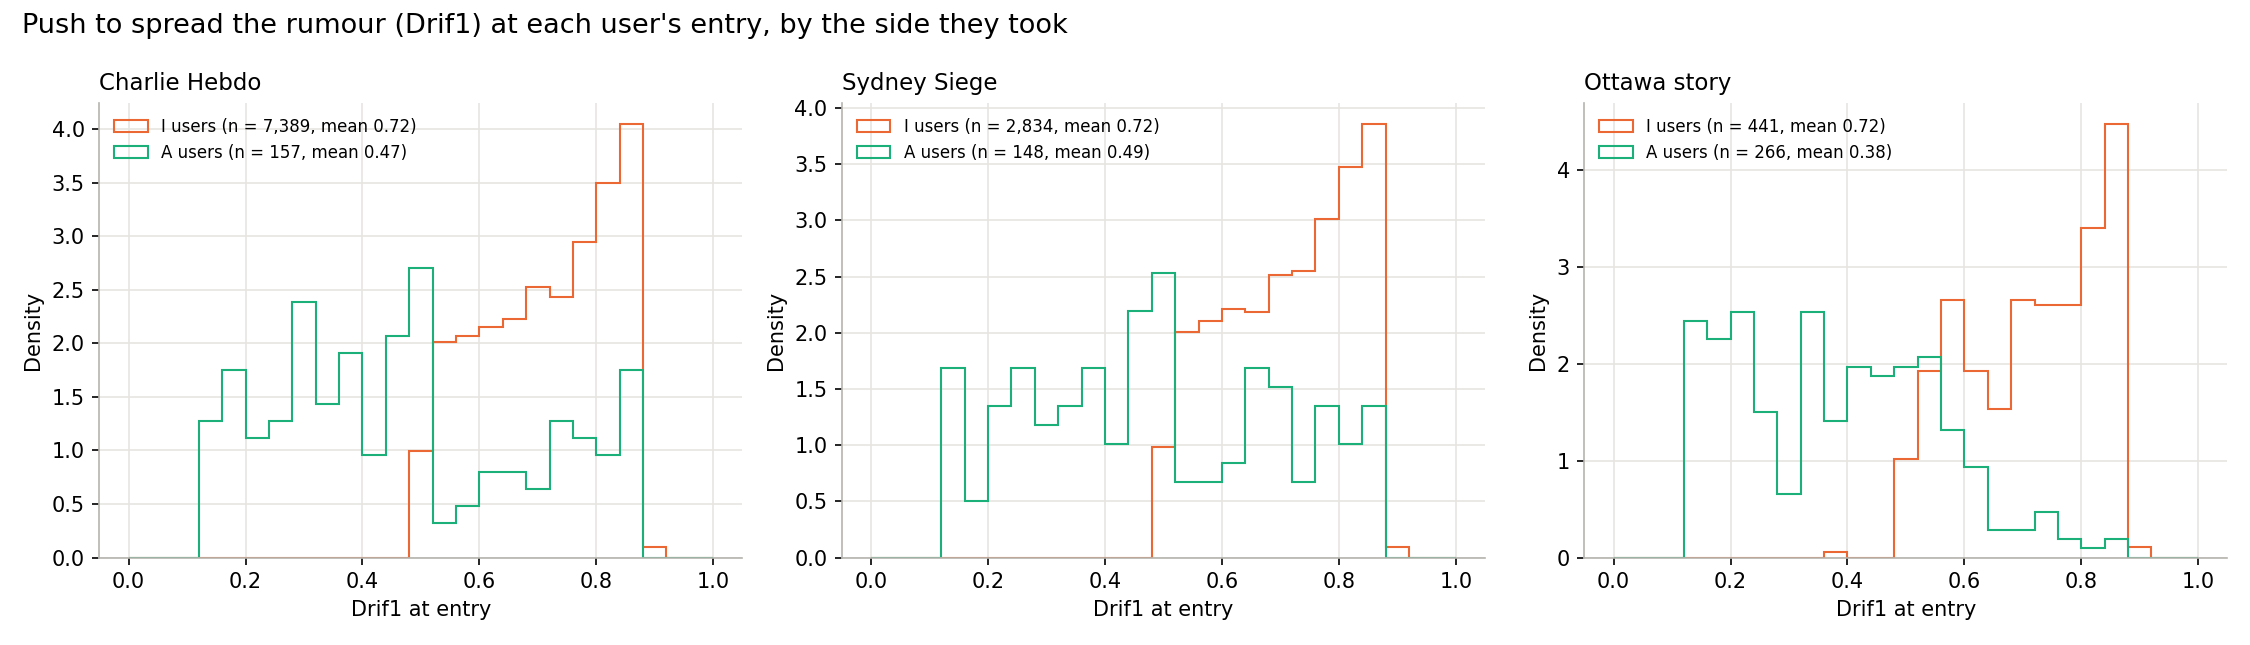

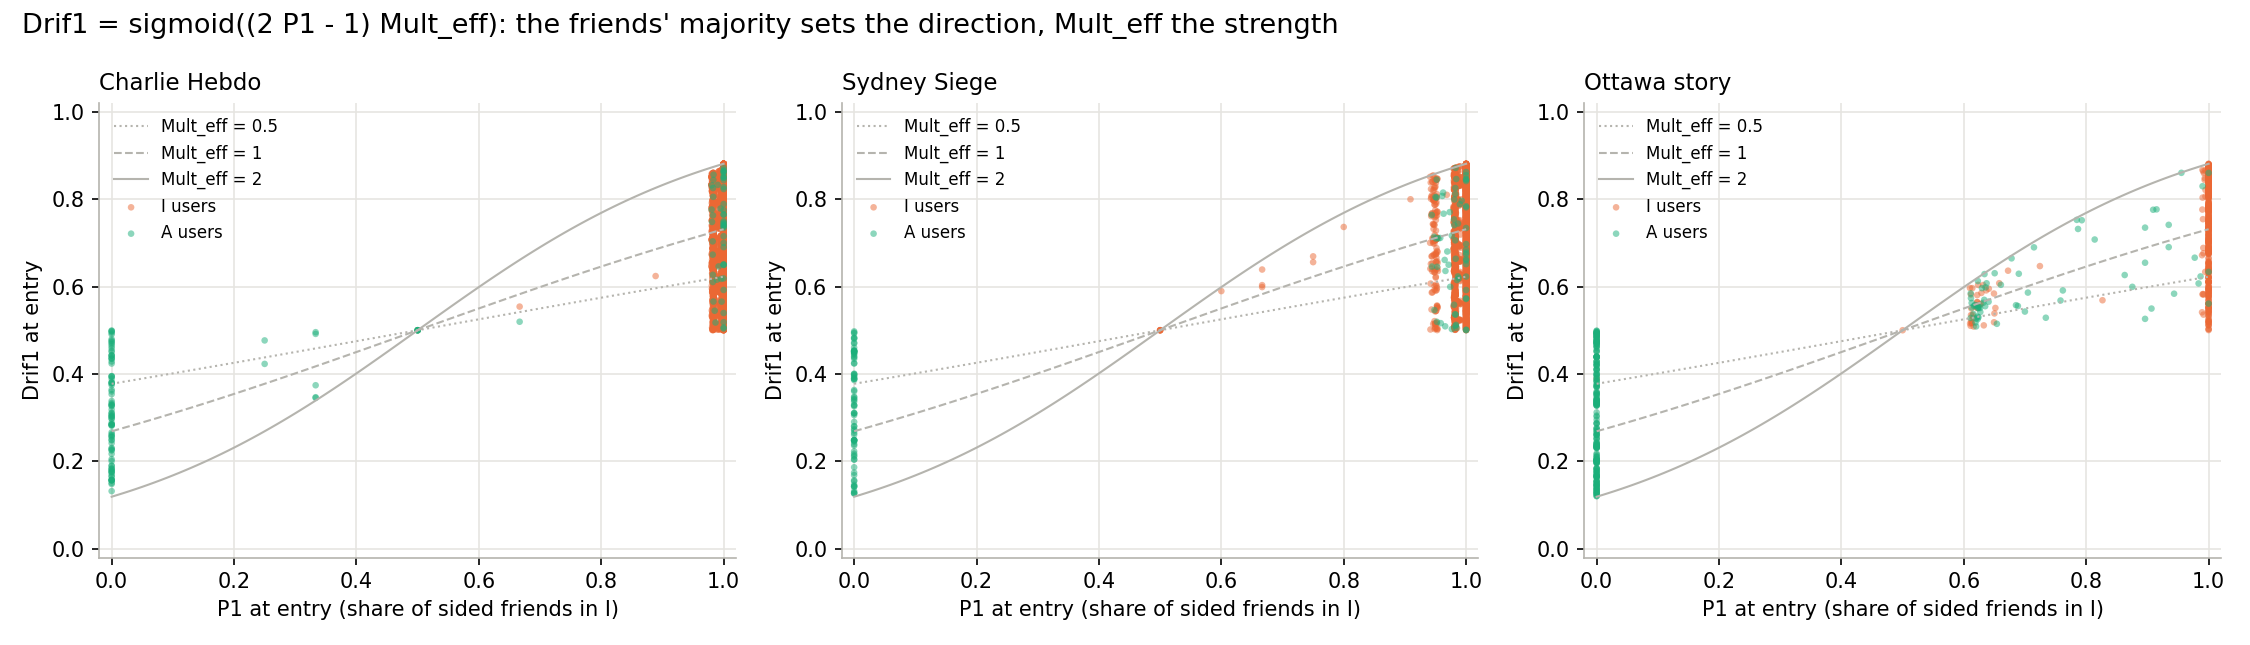

In [5]:
run('src/drive.py --check')
show('phase4_drif_entry.png', 'phase4_drif_vs_p1.png')

## Phase 5: model contest and validation (from checkpoints)

parameter recovery (CH, 5 noise seeds): median |% error| per parameter
                                 true  median_recovered  median_abs_pct_error
model              parameter                                                 
sairh_plus_uniform beta        0.0874            0.0200               77.0866
                   alpha      13.0125           10.4690               90.3939
                   gamma       0.0437            0.0421               97.7100
                   eps         0.0554            0.0493               49.6457
                   kappa      12.4784           18.1710               96.8403
                   theta       0.3179            0.3241                5.4555
                   eta_I       0.0005            0.0097             1666.2882
                   eta_A       0.0000            0.0000                   NaN
sairh_uniform      beta        0.0934            0.0925                1.6704
                   alpha      12.9667           12.1635                

[extra recovery starts] 155 jobs: 155 from checkpoint, 0 to run
            noise_floor_mse  best_random_mse  oracle_mse  random_starts_at_floor  random_starts
noise_seed                                                                                     
1                  0.000083         0.000951    0.000081                       0             30
2                  0.000100         0.000938    0.000098                       0             30
3                  0.000101         0.000443    0.000098                       0             30
4                  0.000100         0.000101    0.000098                       1             30
5                  0.000093         0.000091    0.000091                       1             30
noise_seed       1       2       3      4      5
parameter                                       
alpha        -16.6   -27.7   -45.0   -7.8   -0.9
beta         -98.9   -96.7   -75.3   -3.9    0.8
eps           -2.0    -4.7   -28.6   -7.3    0.2
eta_A          NaN 

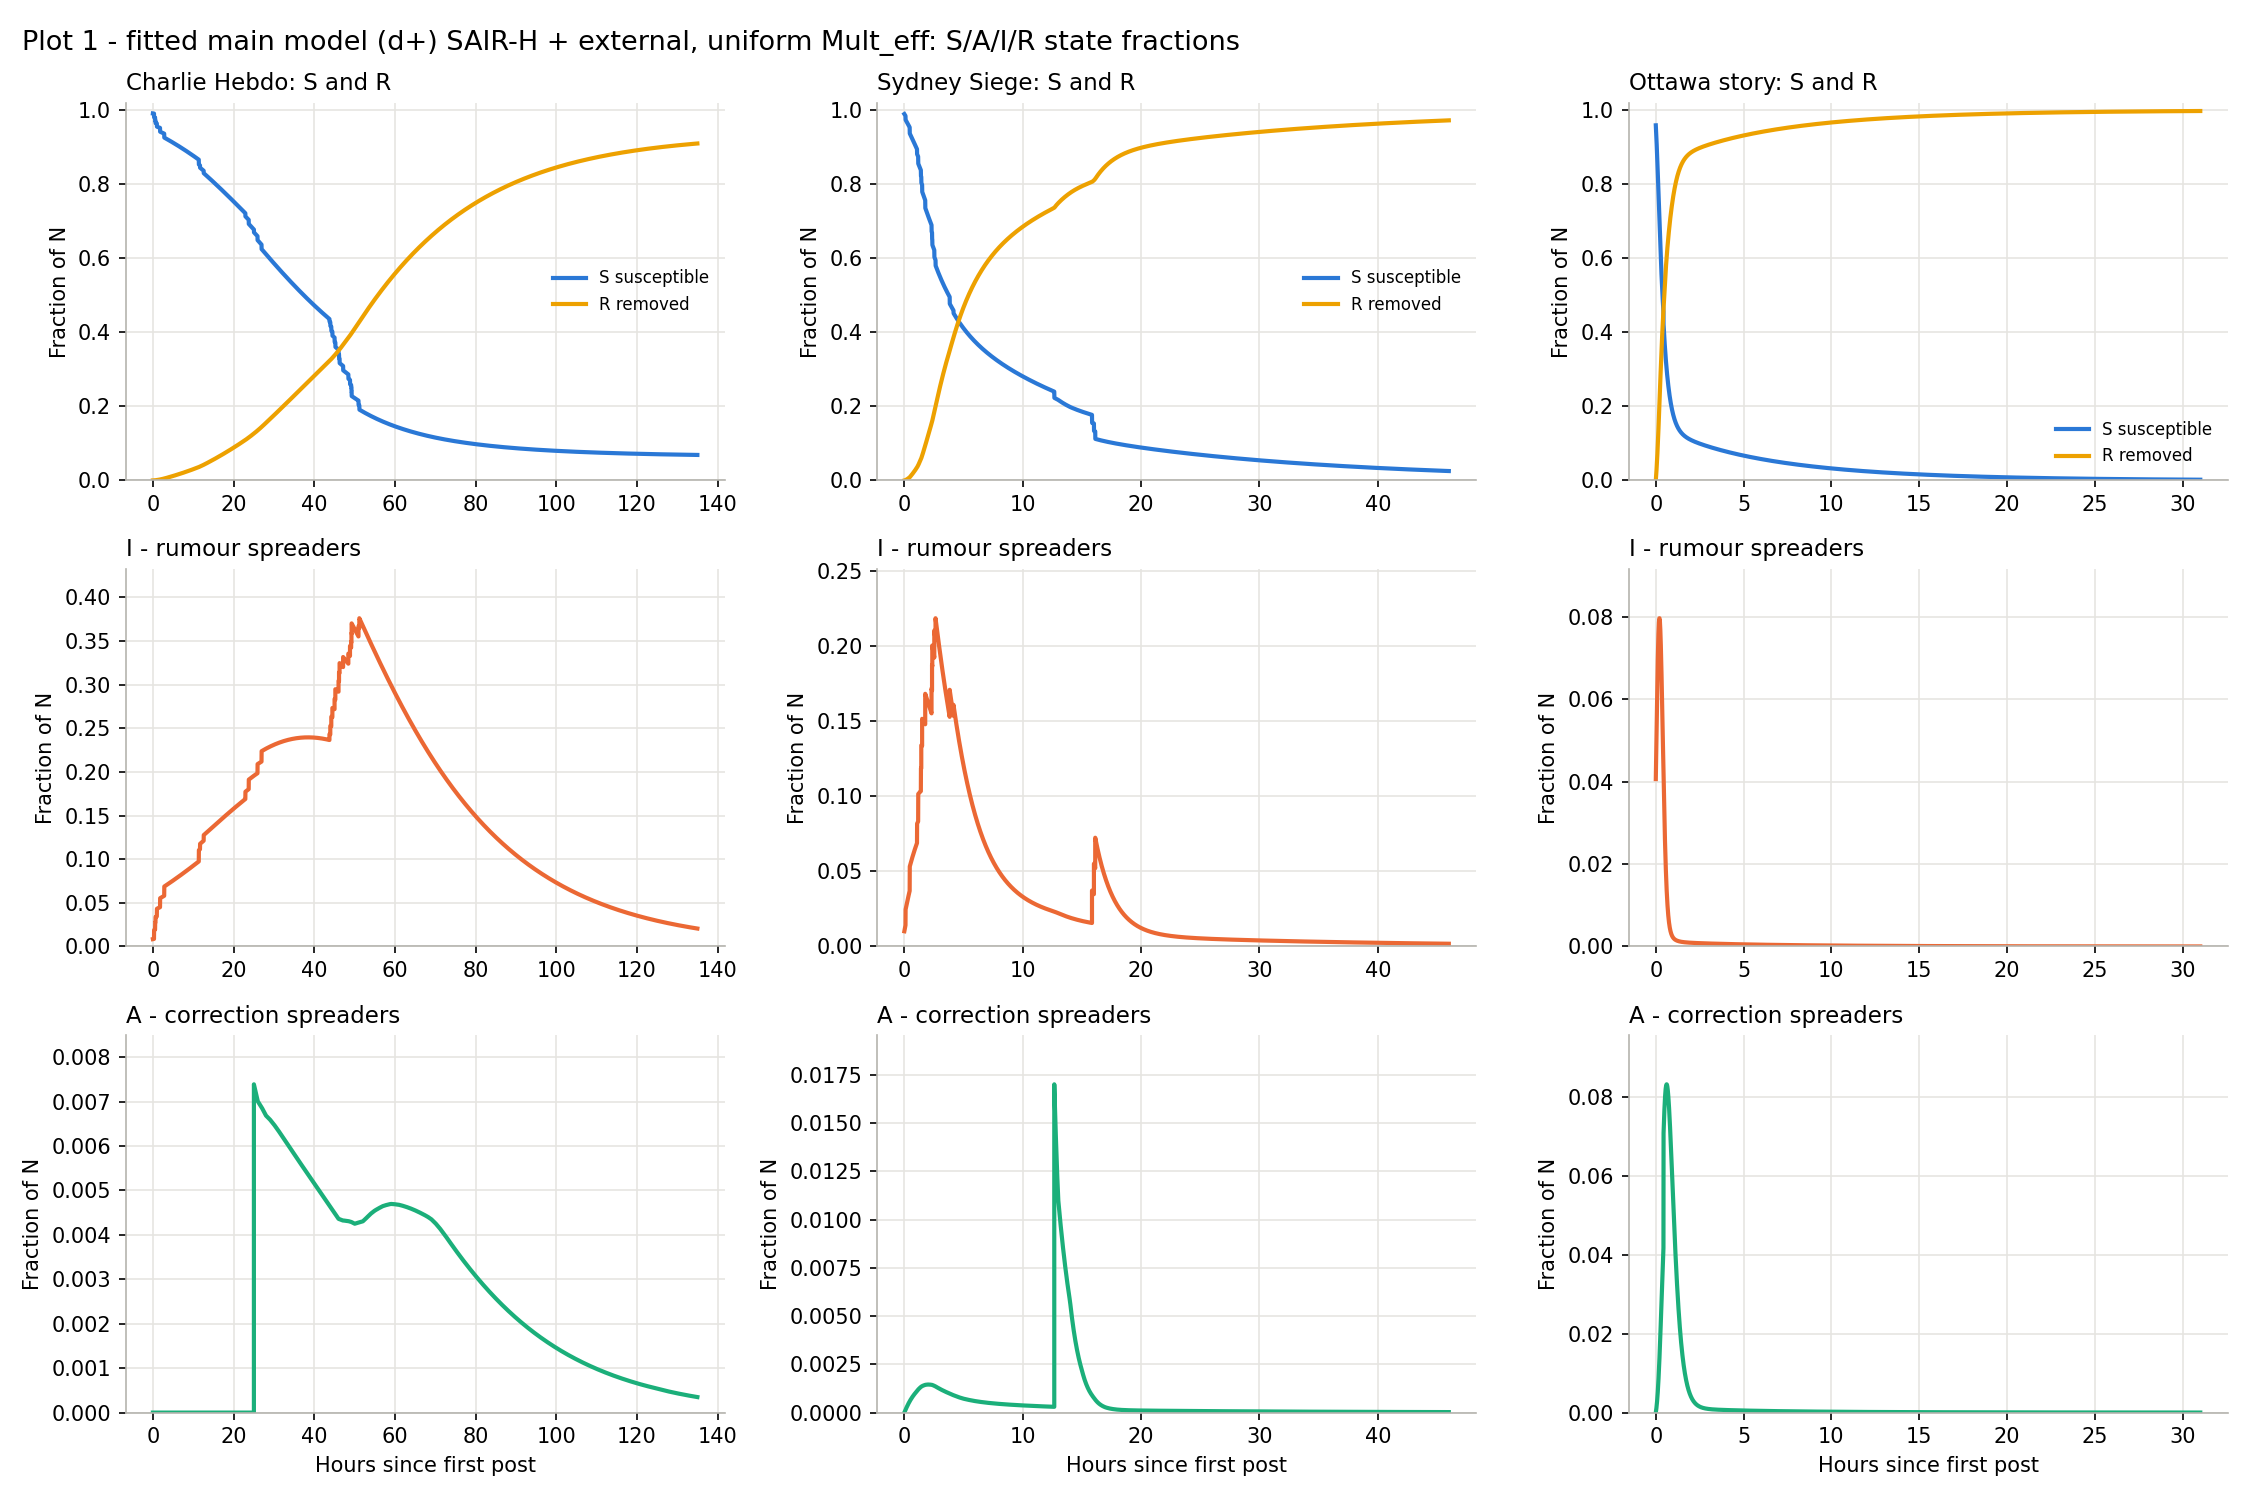

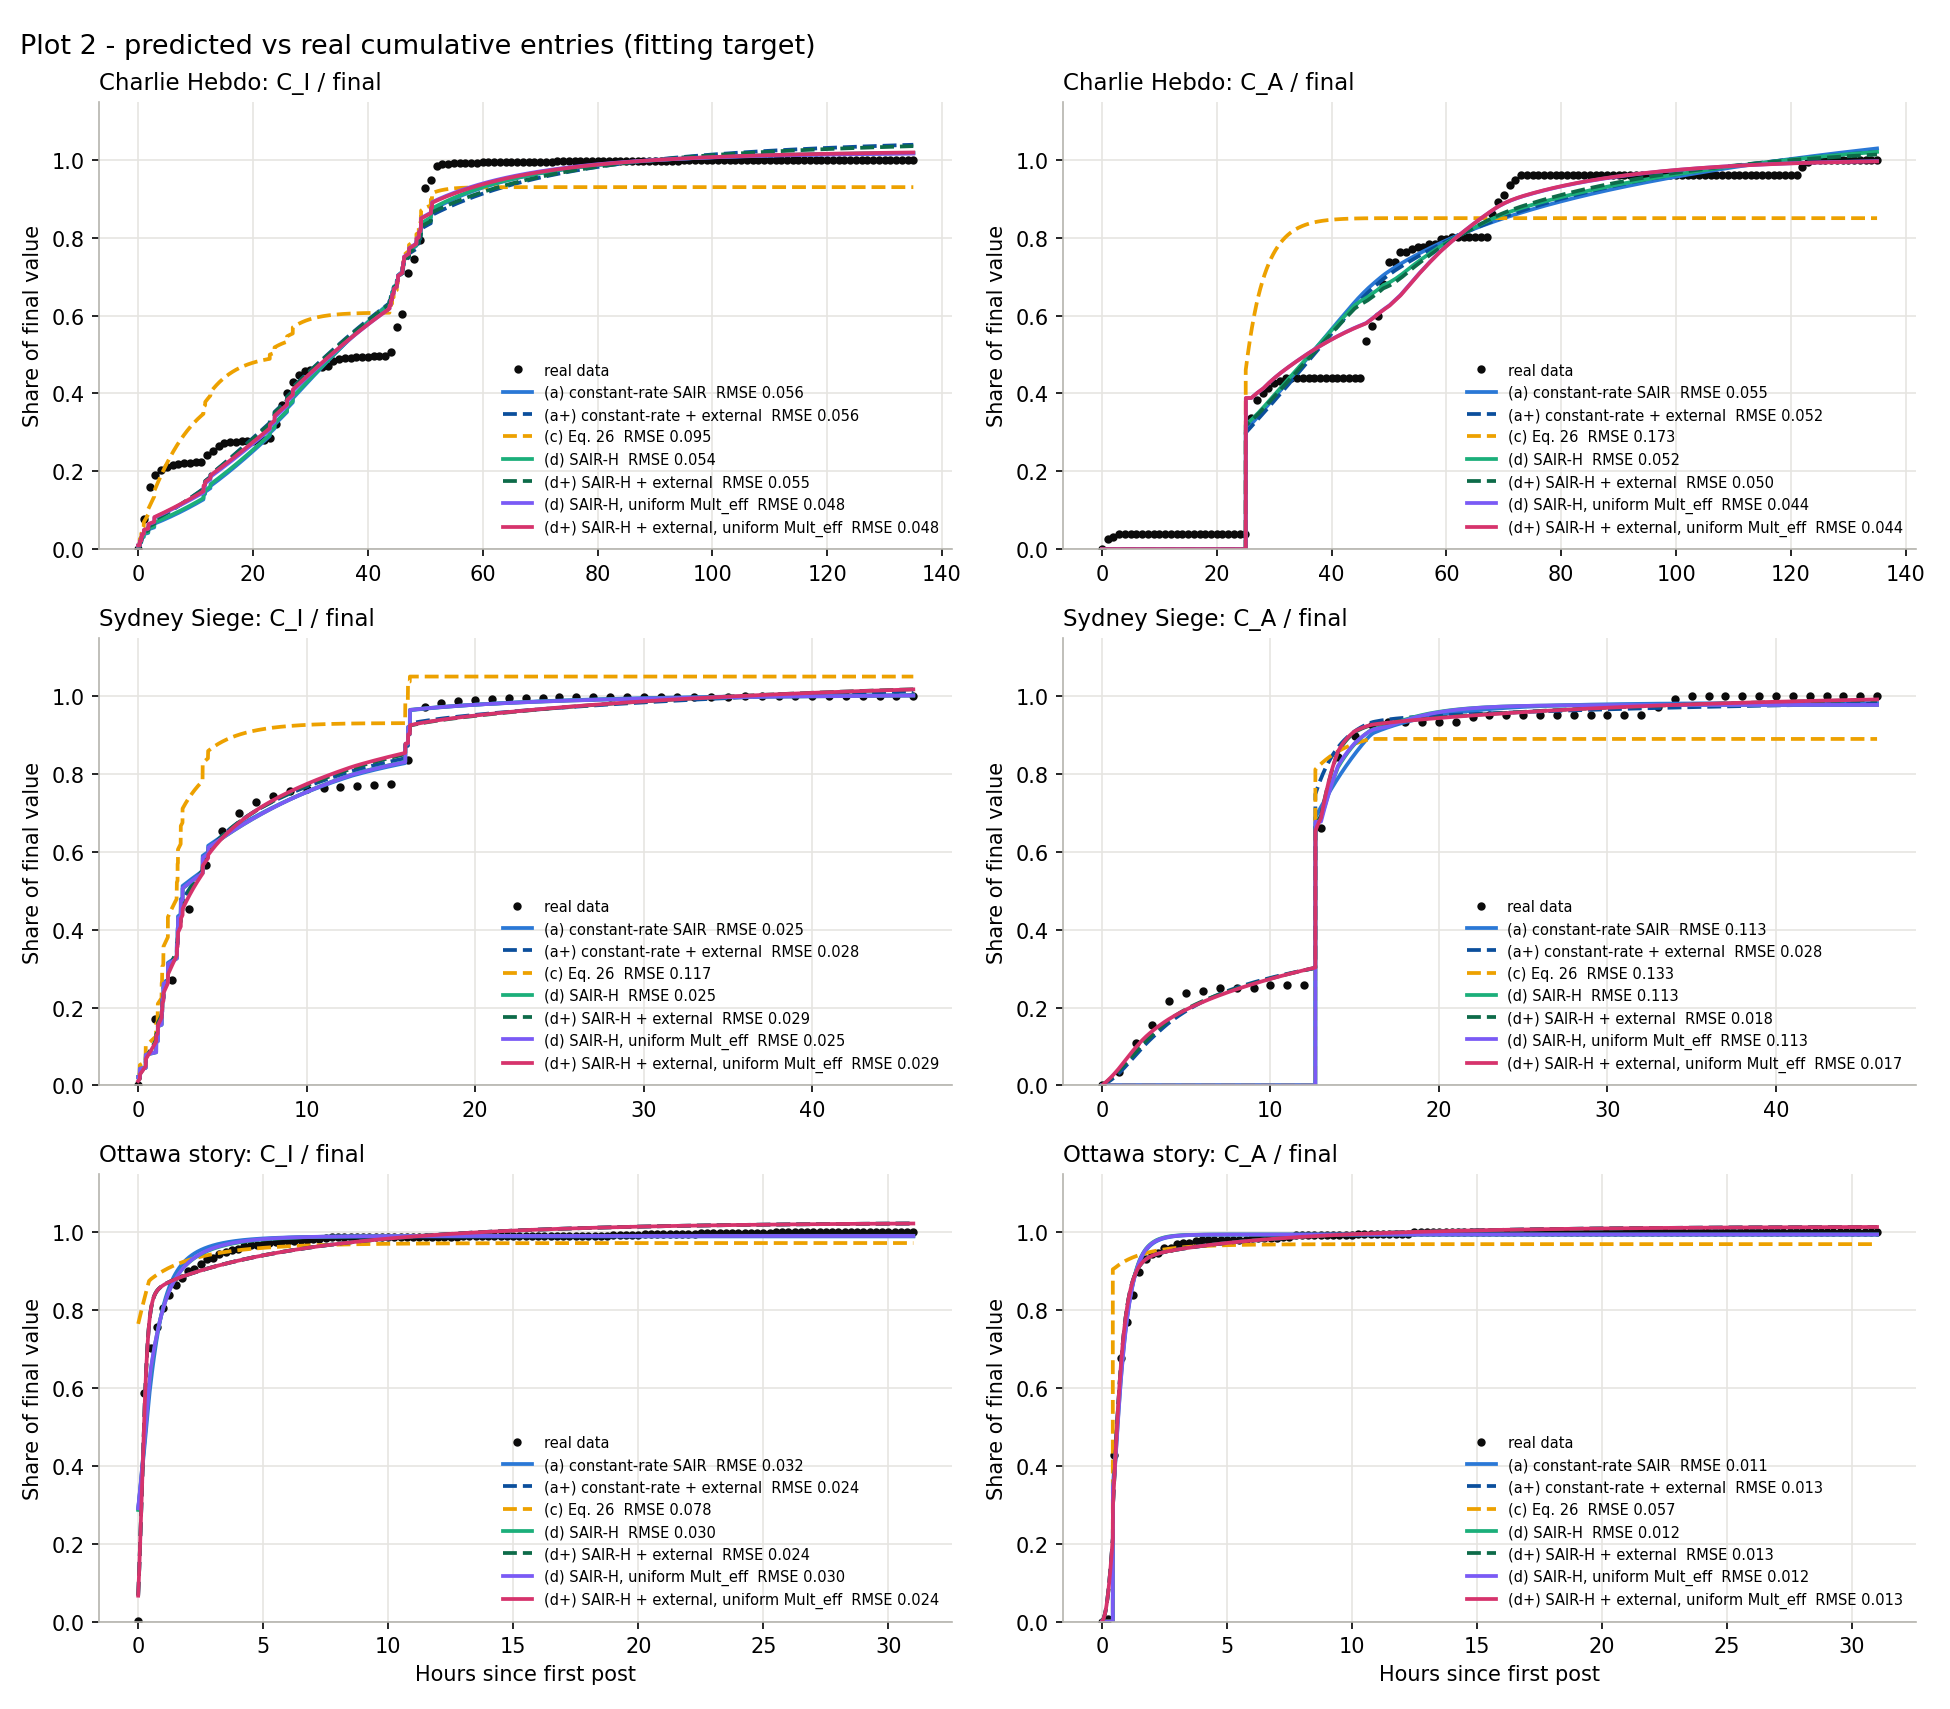

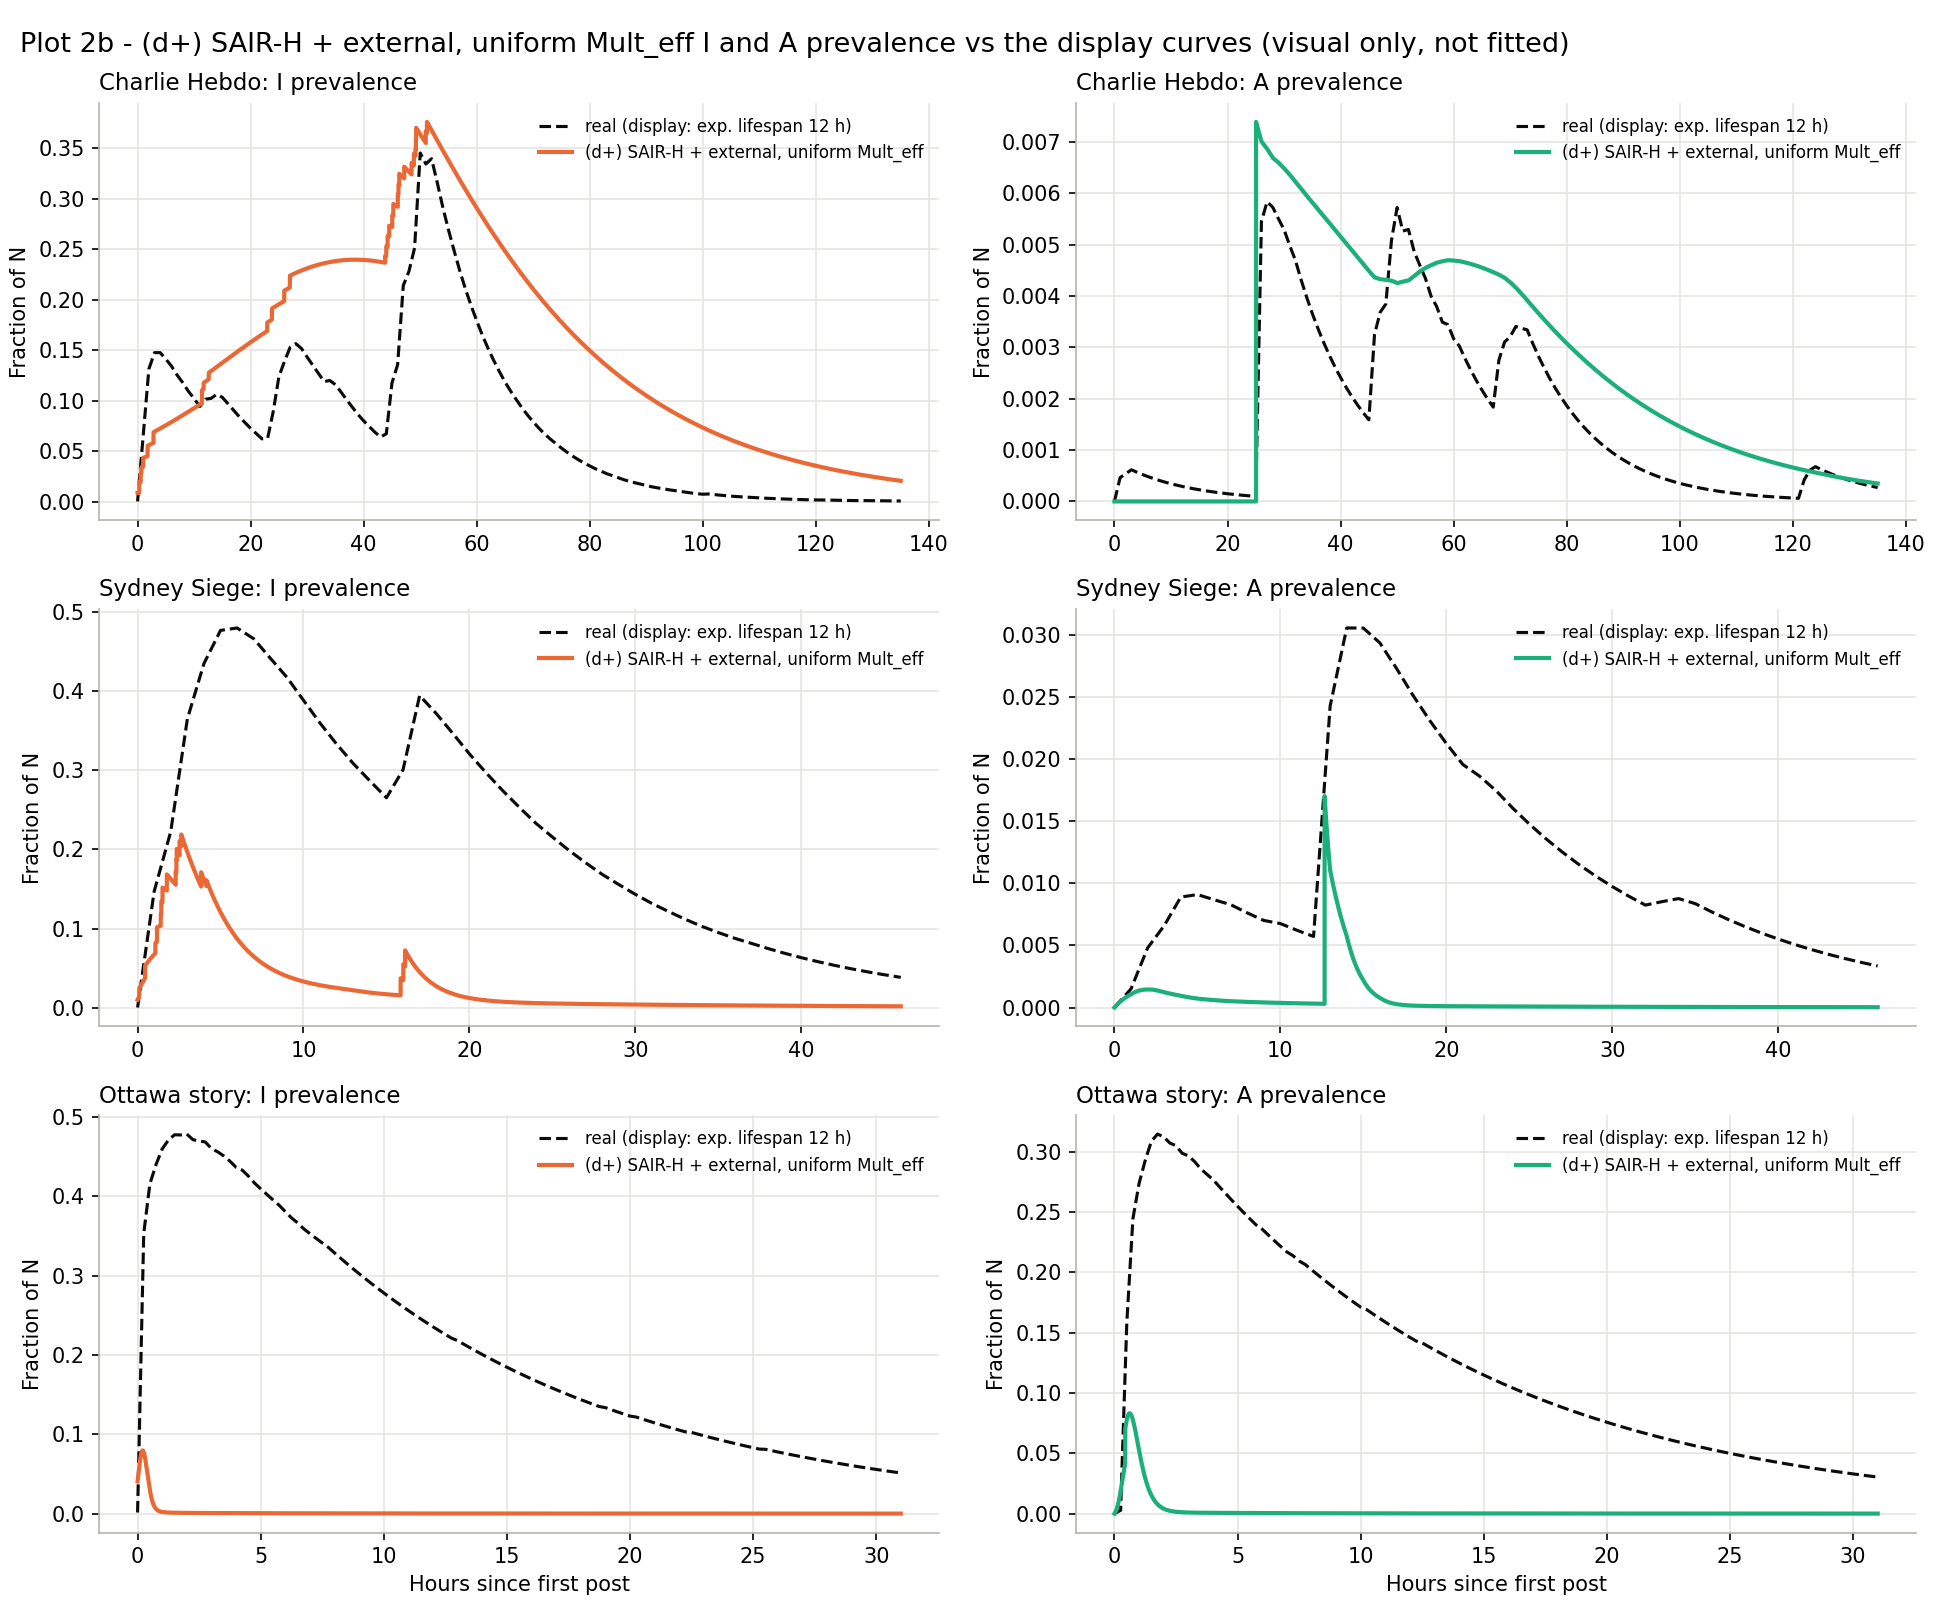

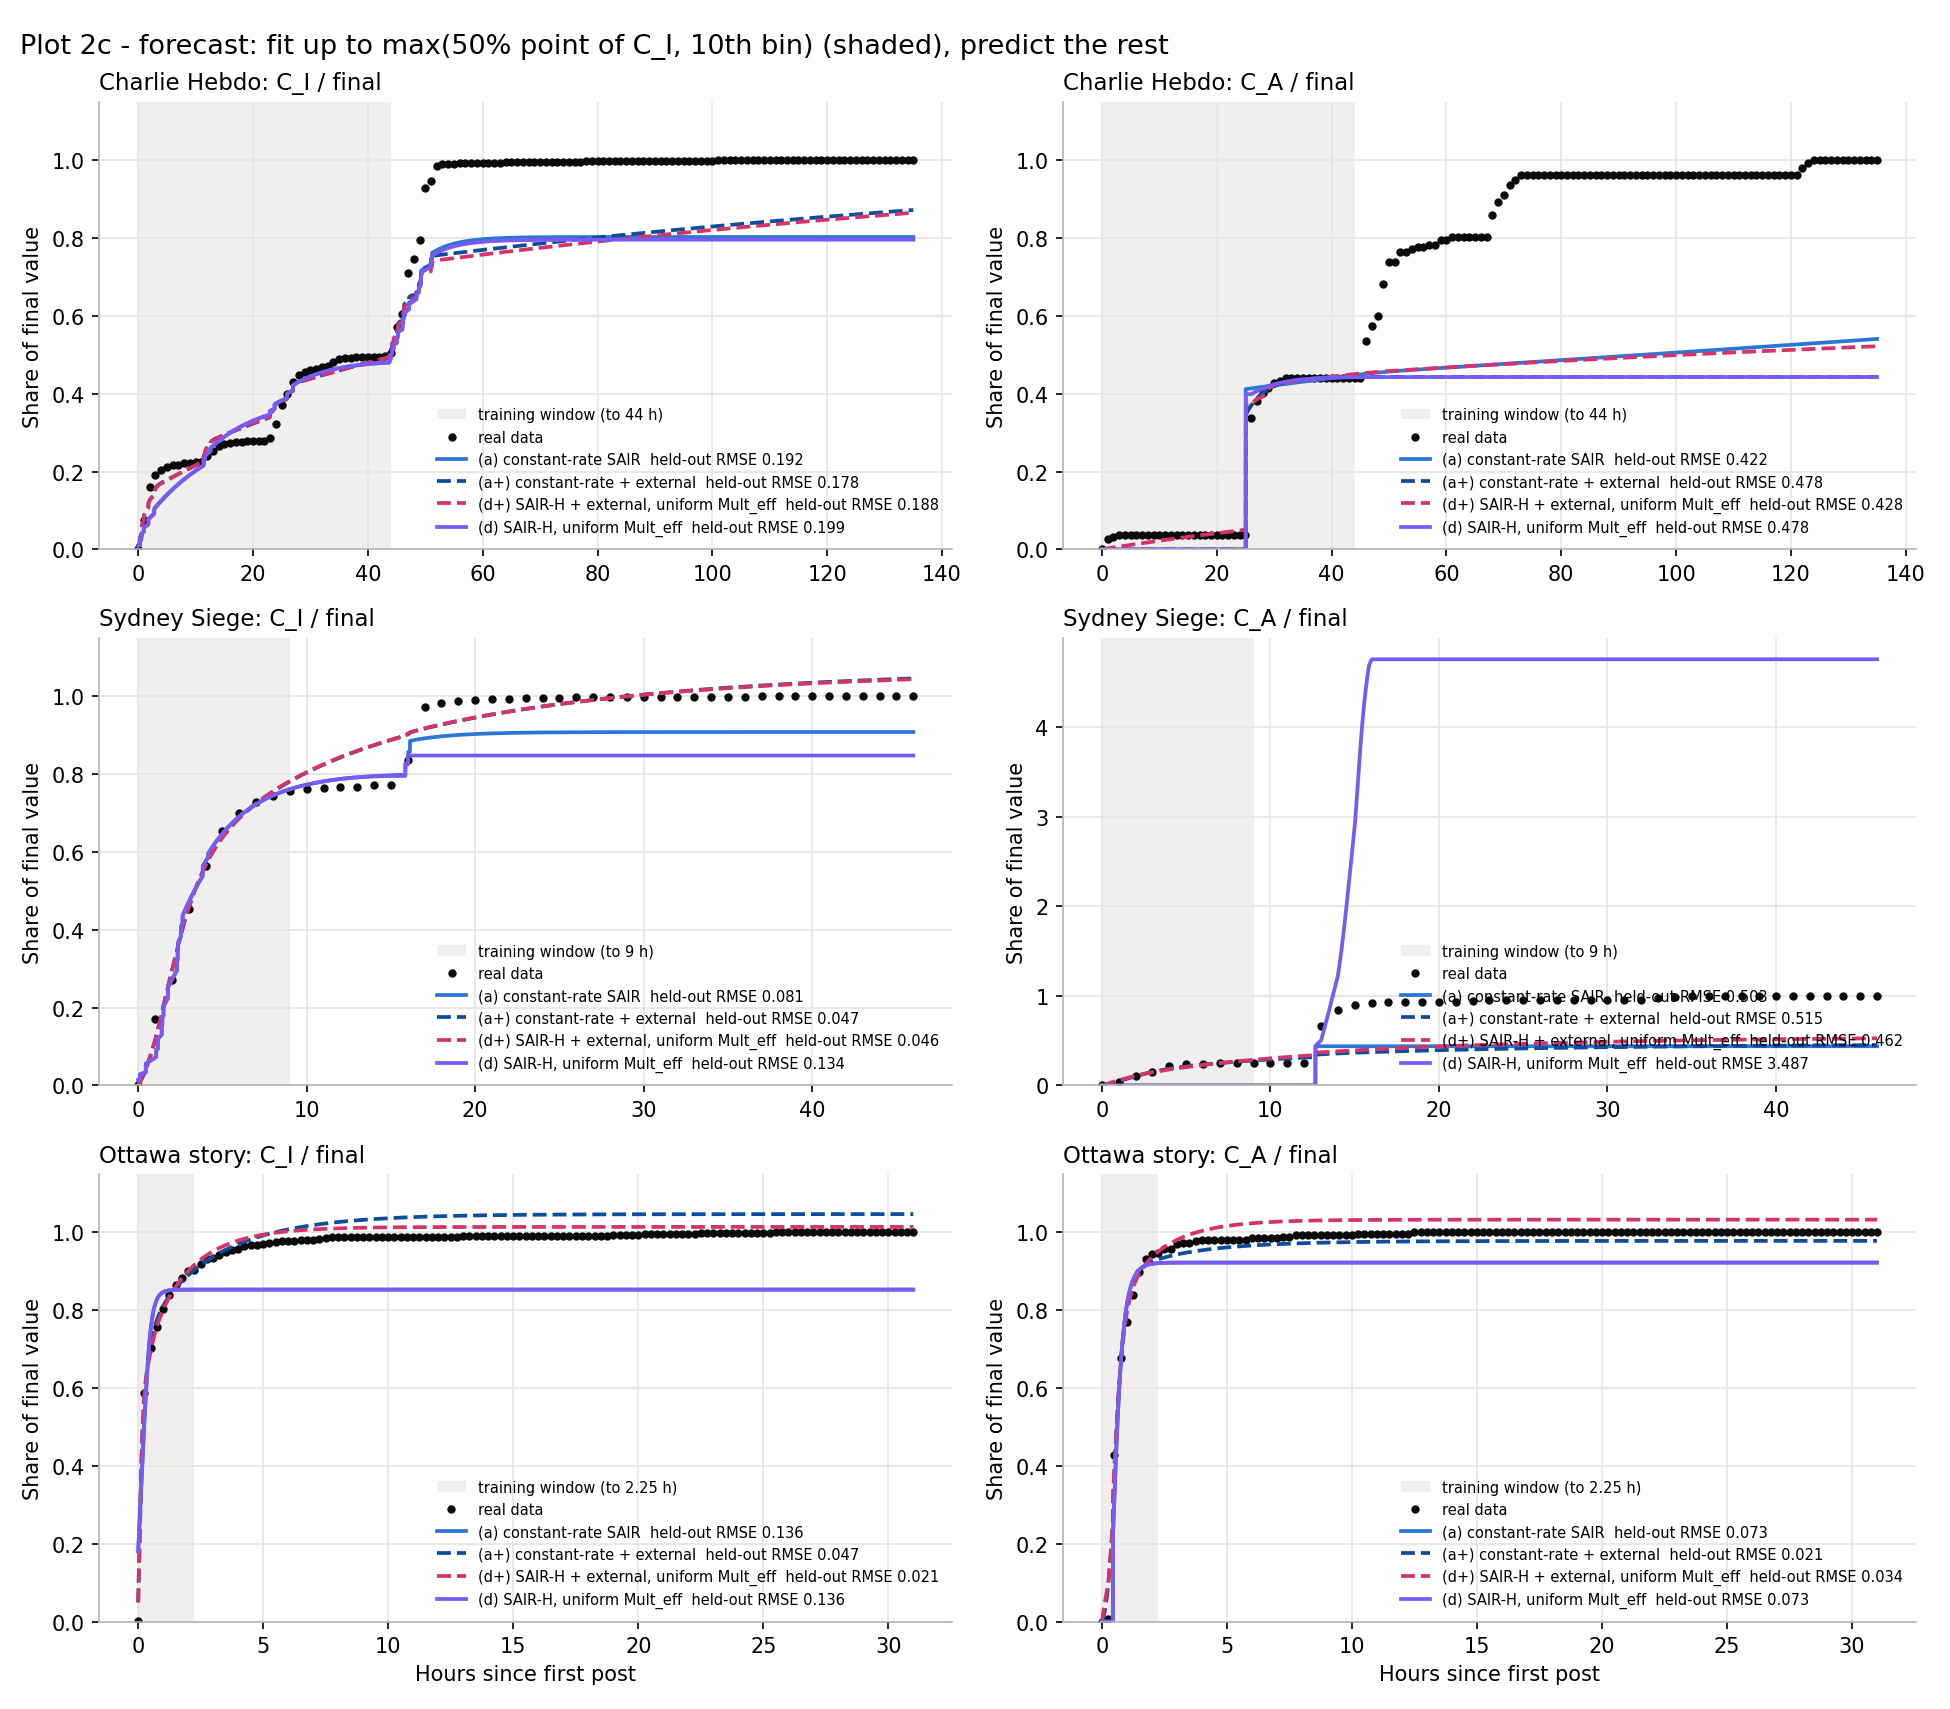

In [6]:
run('src/sair.py --check', tail=20)
run('src/sair.py --recovery-extra', tail=20)
show('phase5_plot1_states.png', 'phase5_plot2_cumulative_fit.png', 'phase5_plot2b_prevalence.png', 'phase5_plot2c_forecast.png')

## Phase 6: ablation


--- Phase 6 check ---
charliehebdo           OK  sairh_plus_uniform (main): full model == Phase 5 run (SSE 0.578302); 8 knock-outs change only their input; max|sum-1|=1.3e-14
charliehebdo           OK  sairh_plus (paper-faithful (d+)): full model == Phase 5 run (SSE 0.742464); 8 knock-outs change only their input; max|sum-1|=1.6e-14
charliehebdo           OK  sairh_uniform (secondary (main under D66)): full model == Phase 5 run (SSE 0.578813); 7 knock-outs change only their input; max|sum-1|=1.4e-14
sydneysiege            OK  sairh_plus_uniform (main): full model == Phase 5 run (SSE 0.054413); 8 knock-outs change only their input; max|sum-1|=1.0e-14
sydneysiege            OK  sairh_plus (paper-faithful (d+)): full model == Phase 5 run (SSE 0.055771); 8 knock-outs change only their input; max|sum-1|=1.3e-14
sydneysiege            OK  sairh_uniform (secondary (main under D66)): full model == Phase 5 run (SSE 0.628562); 7 knock-outs change only their input; max|sum-1|=2.2e-14
story_three

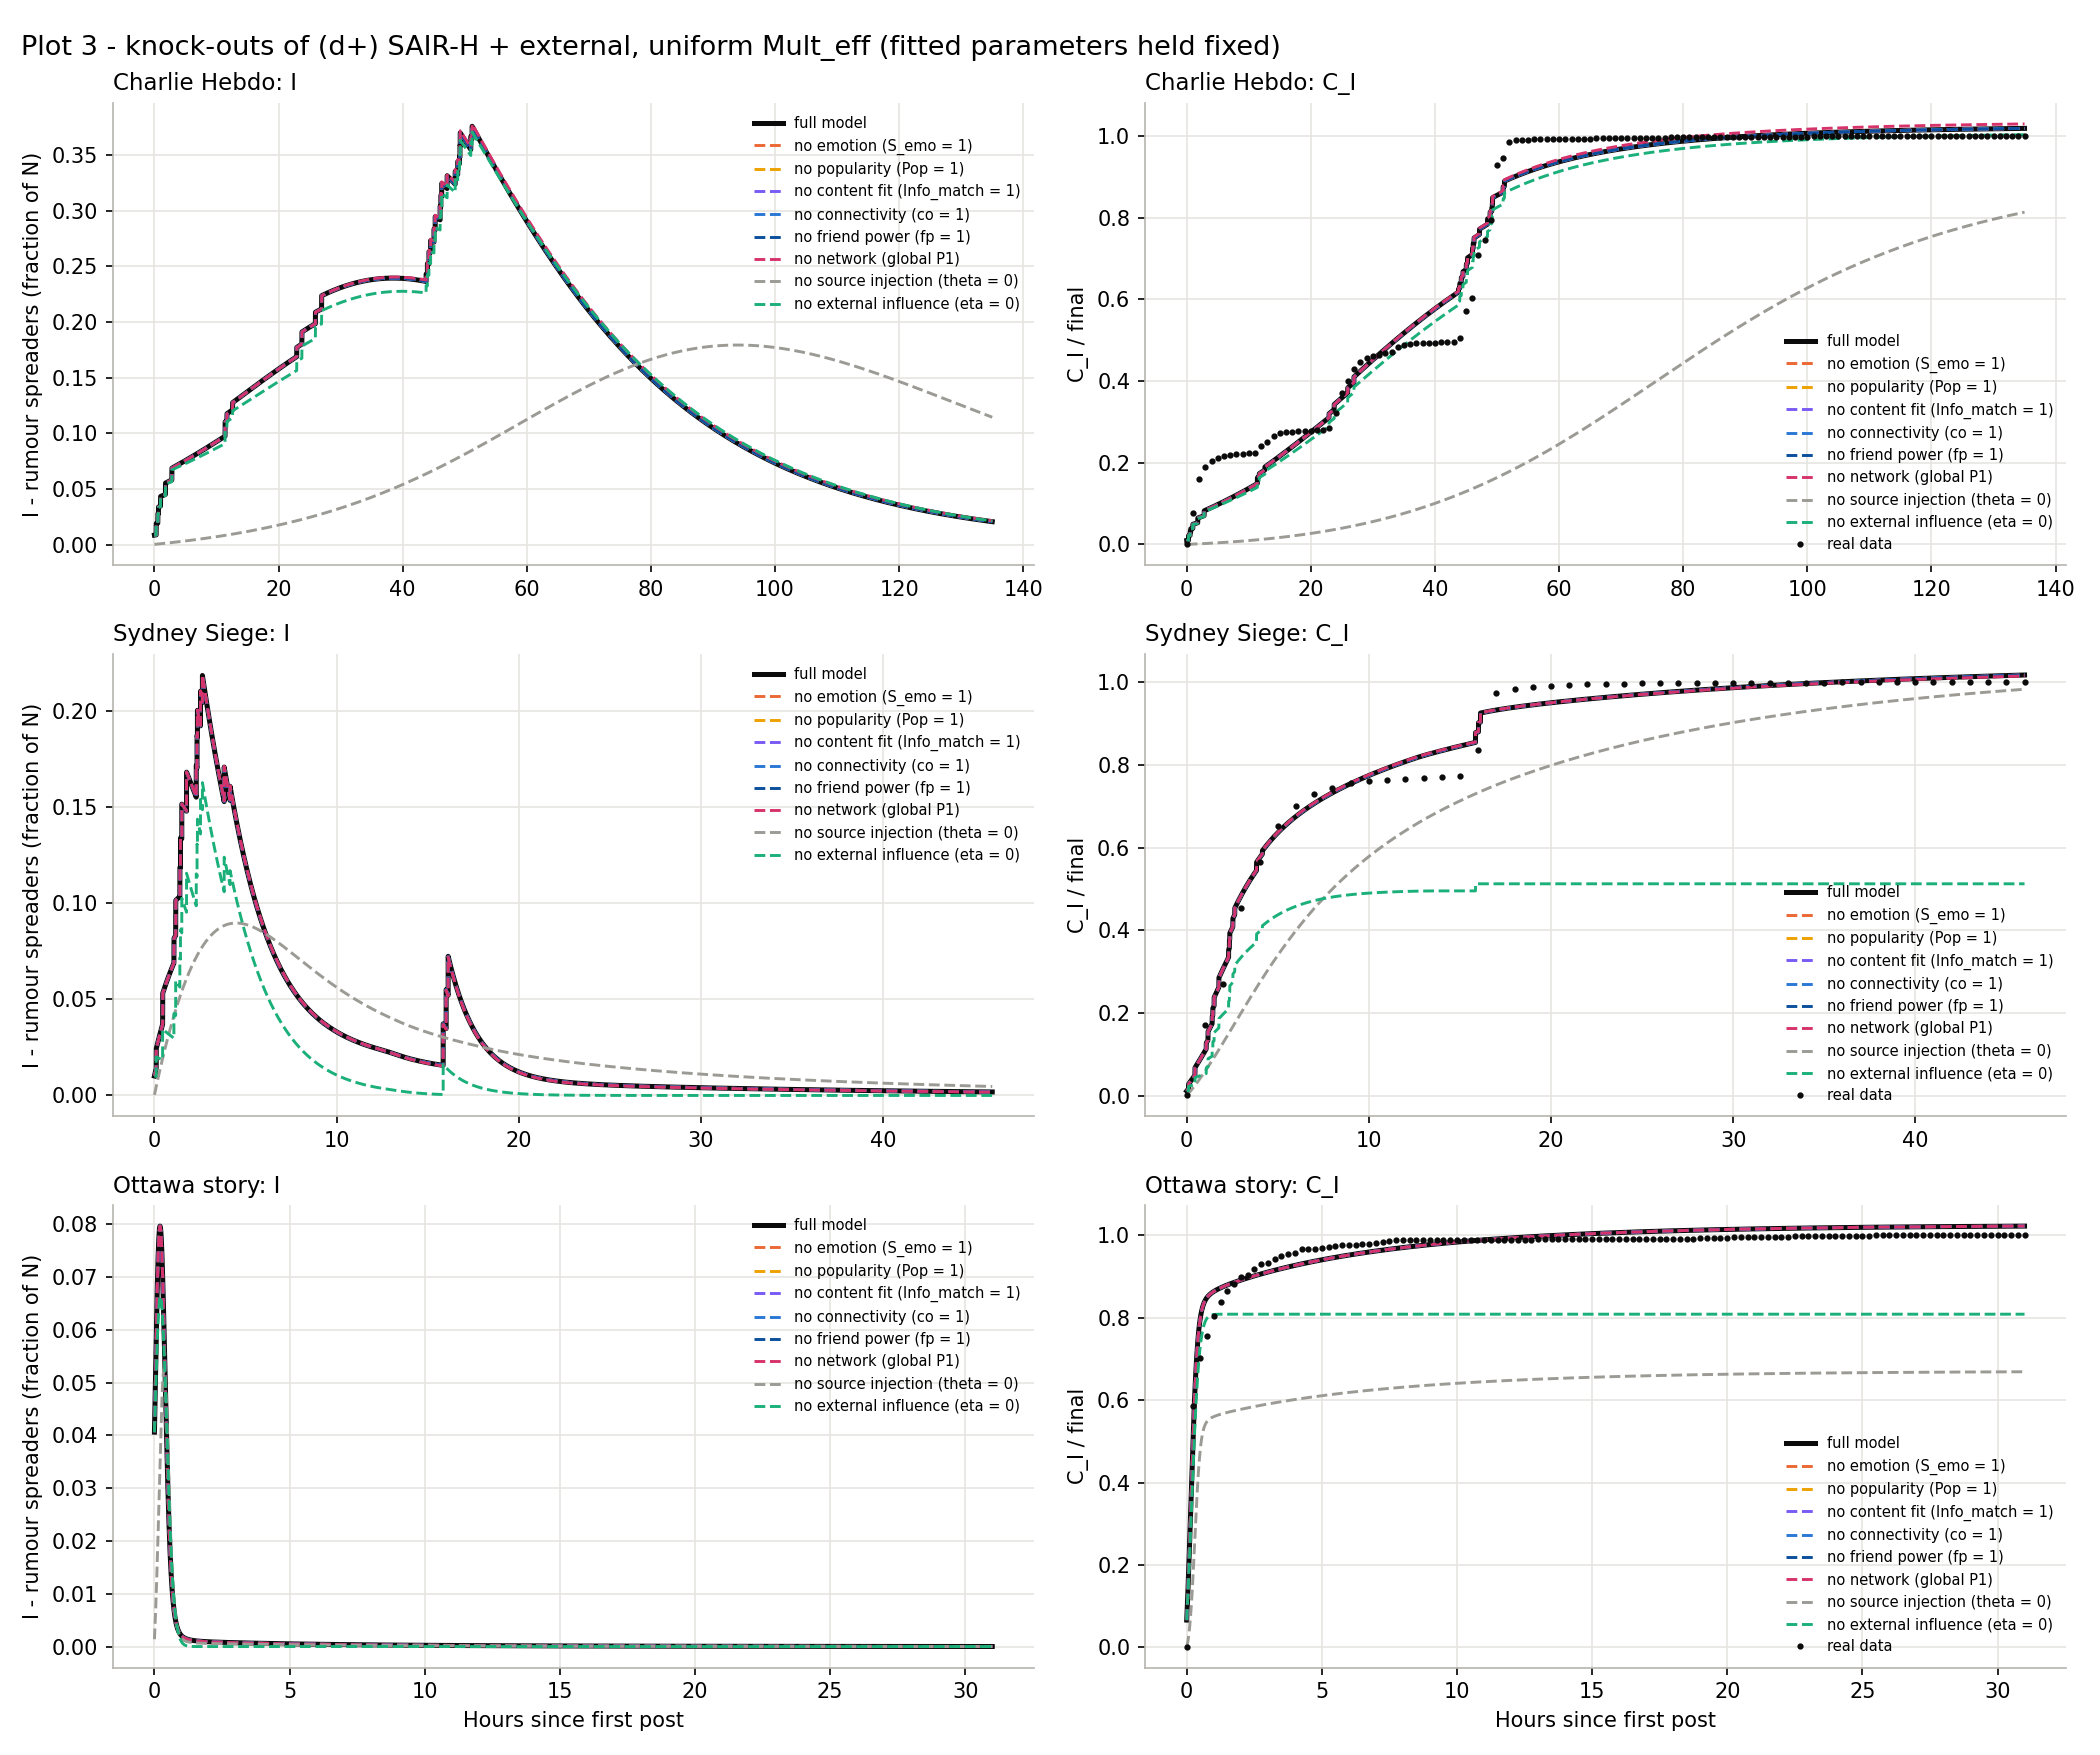

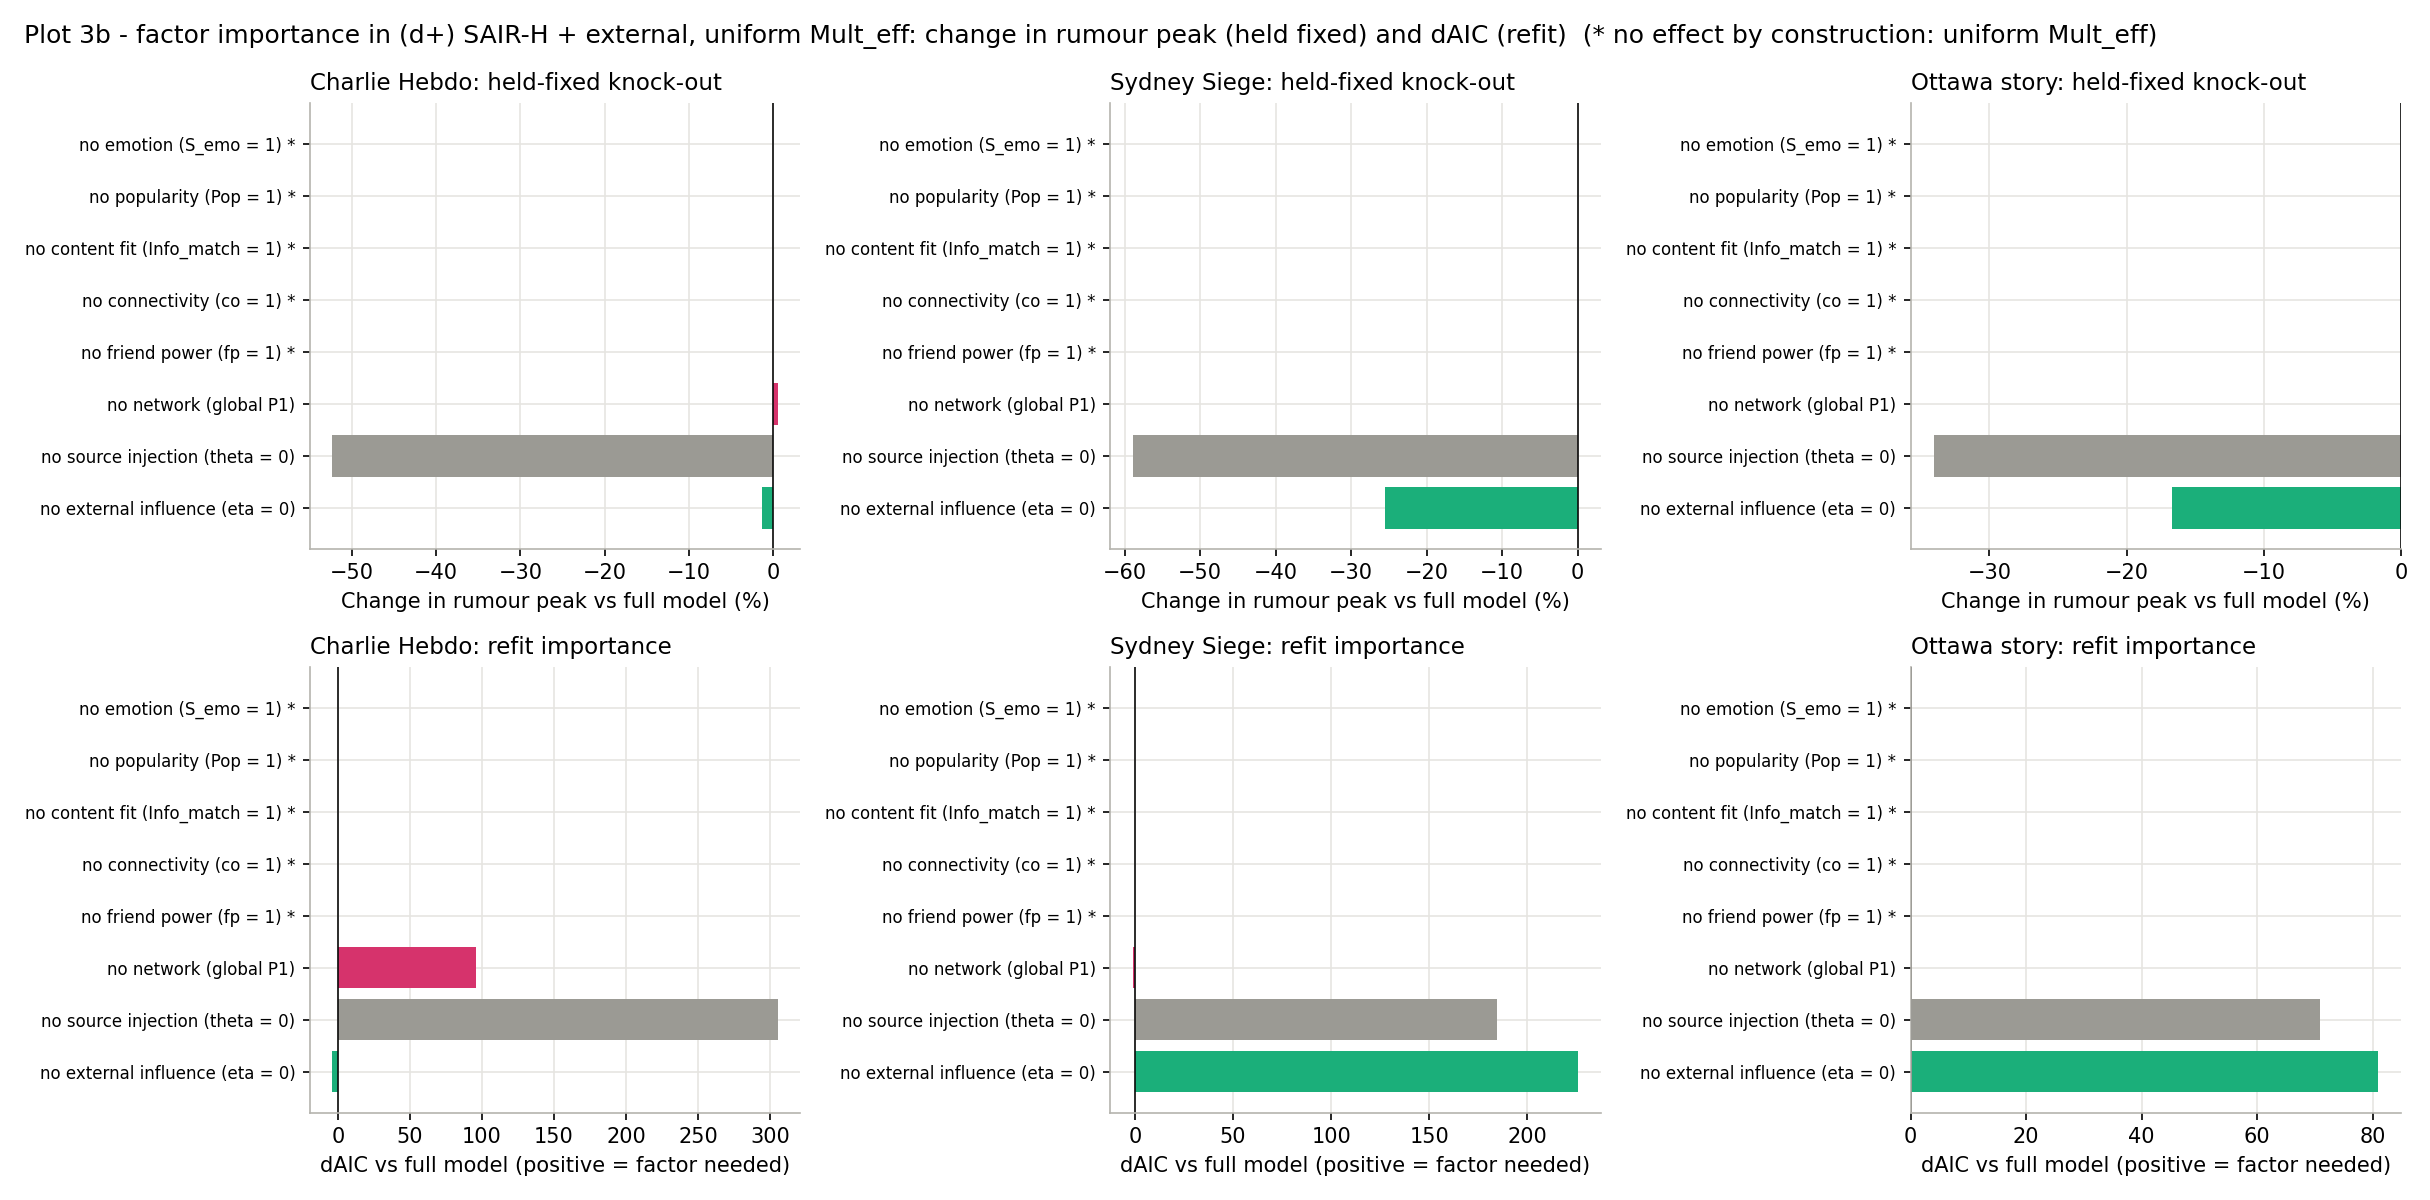

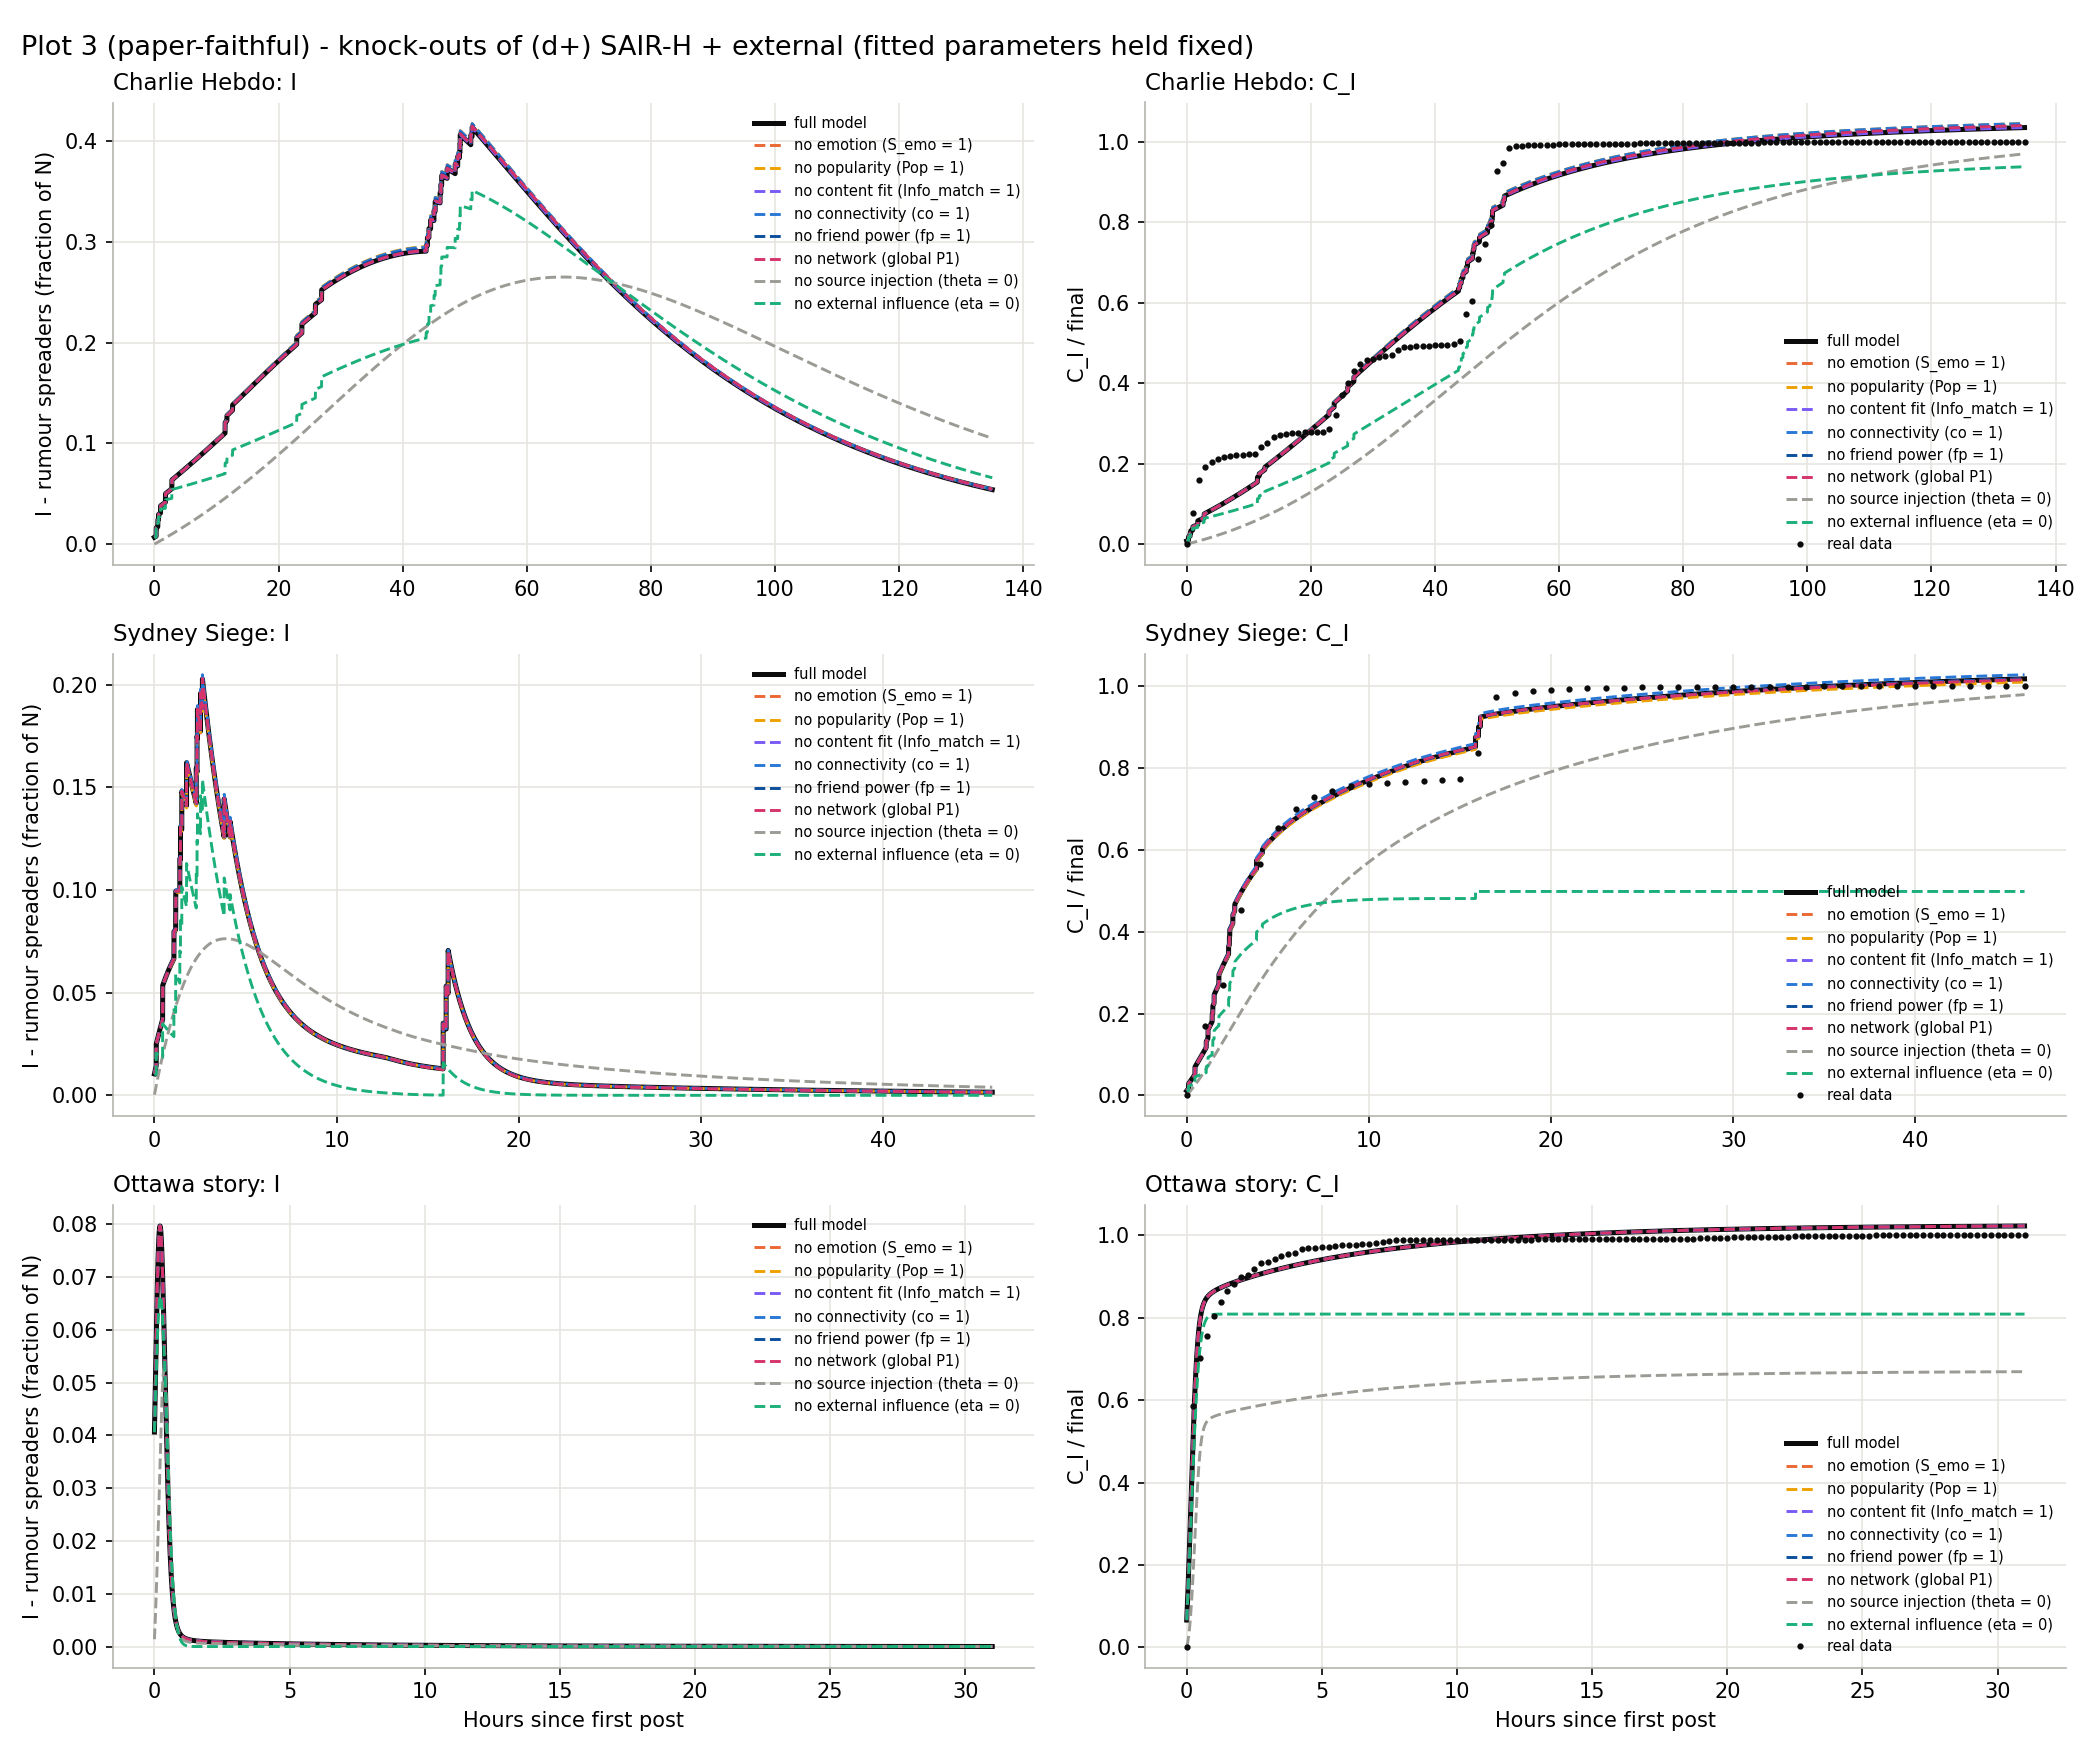

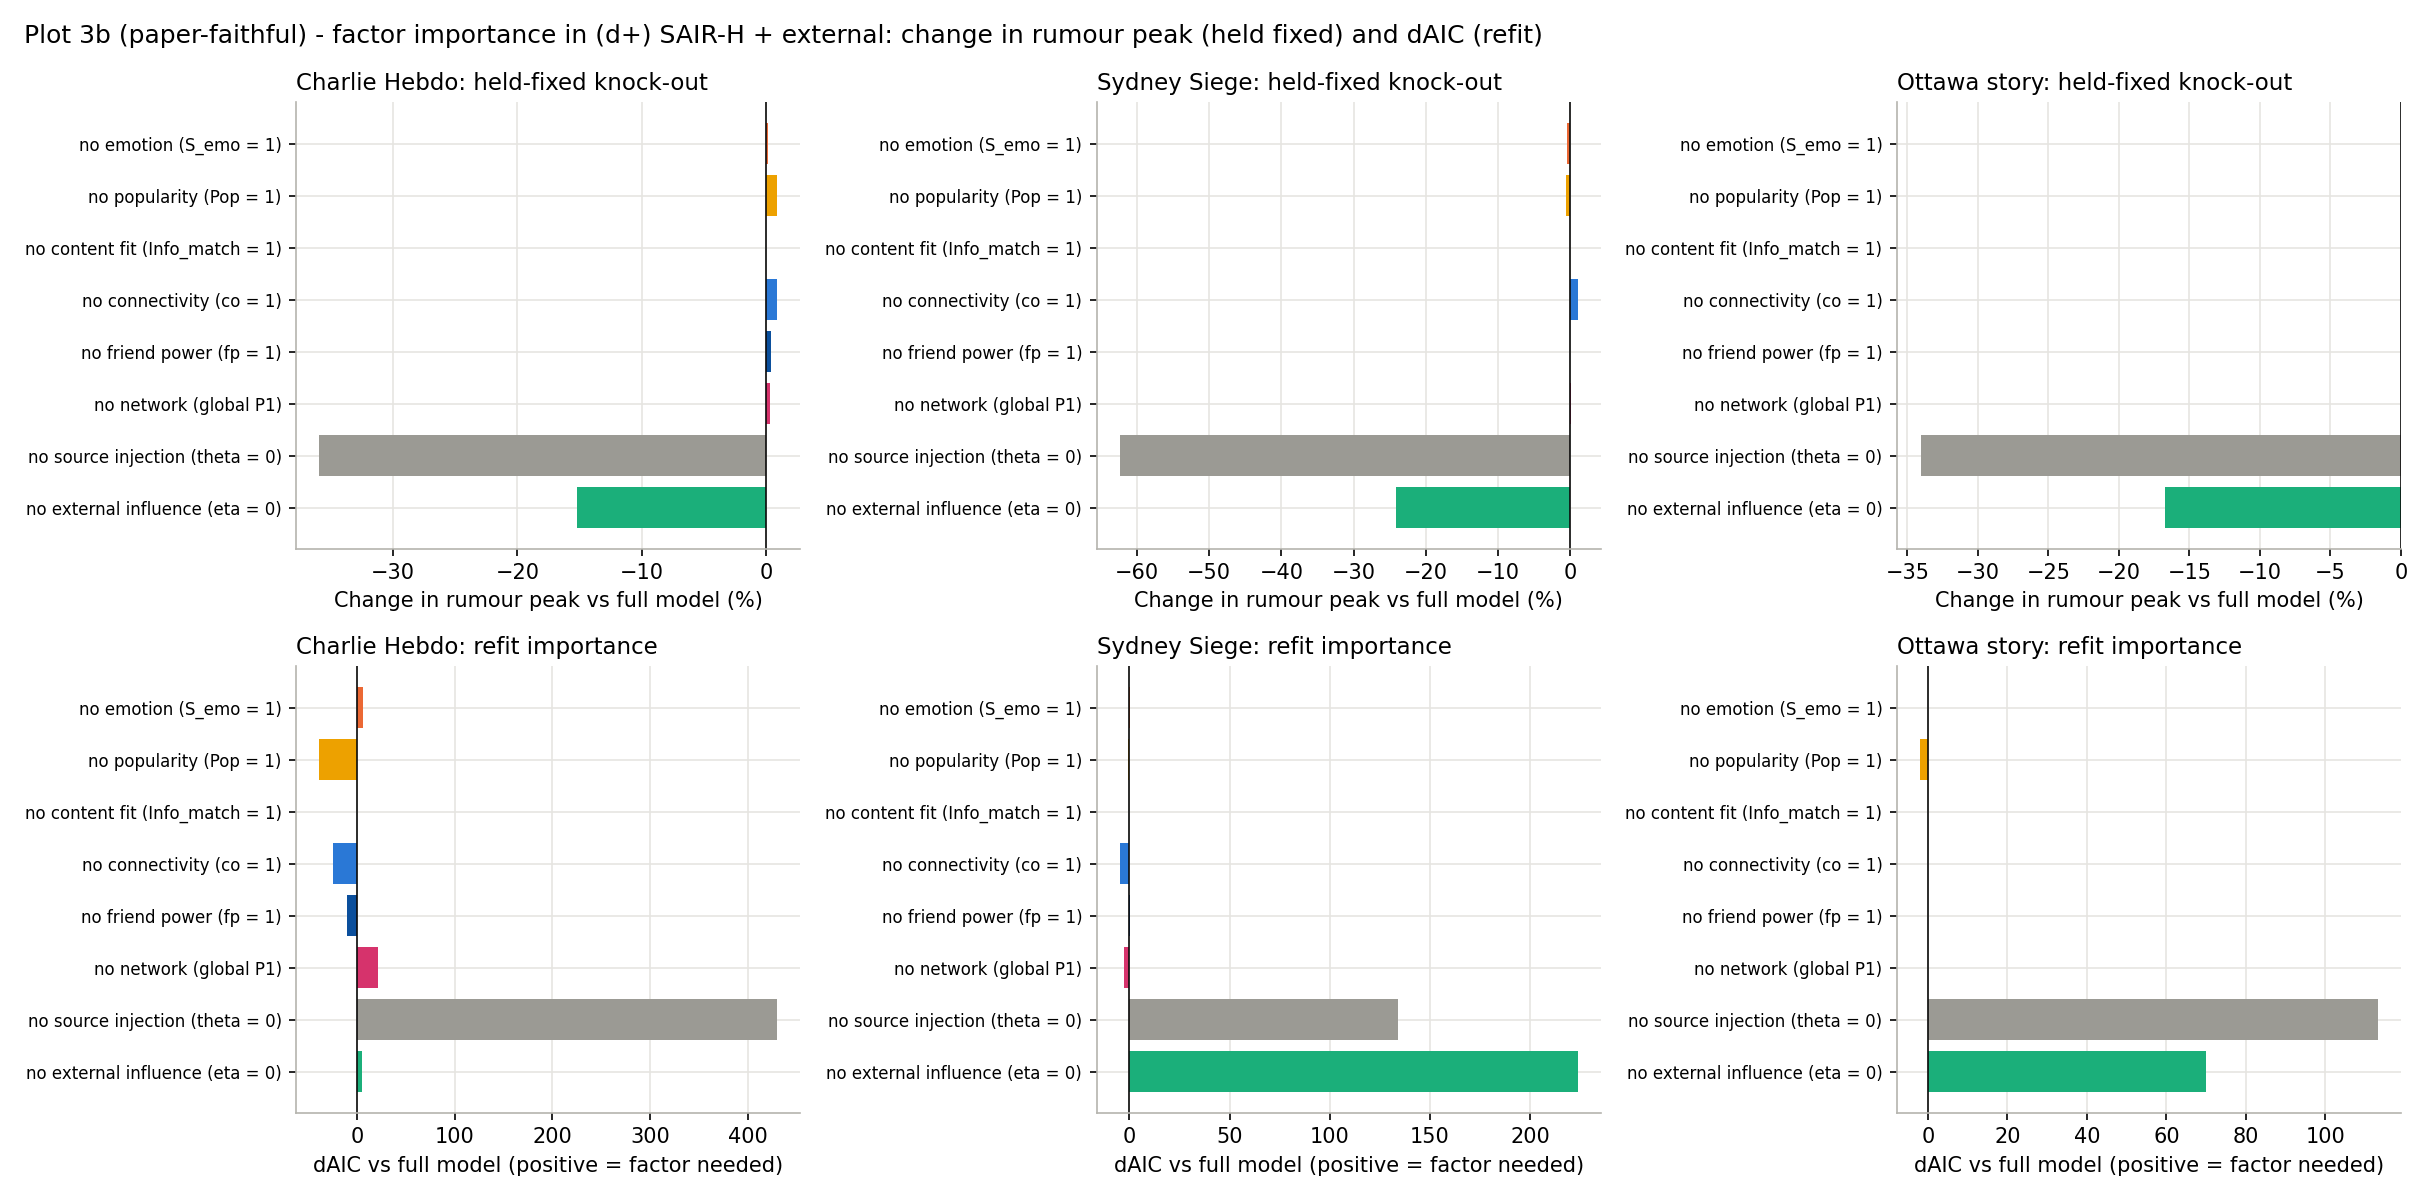

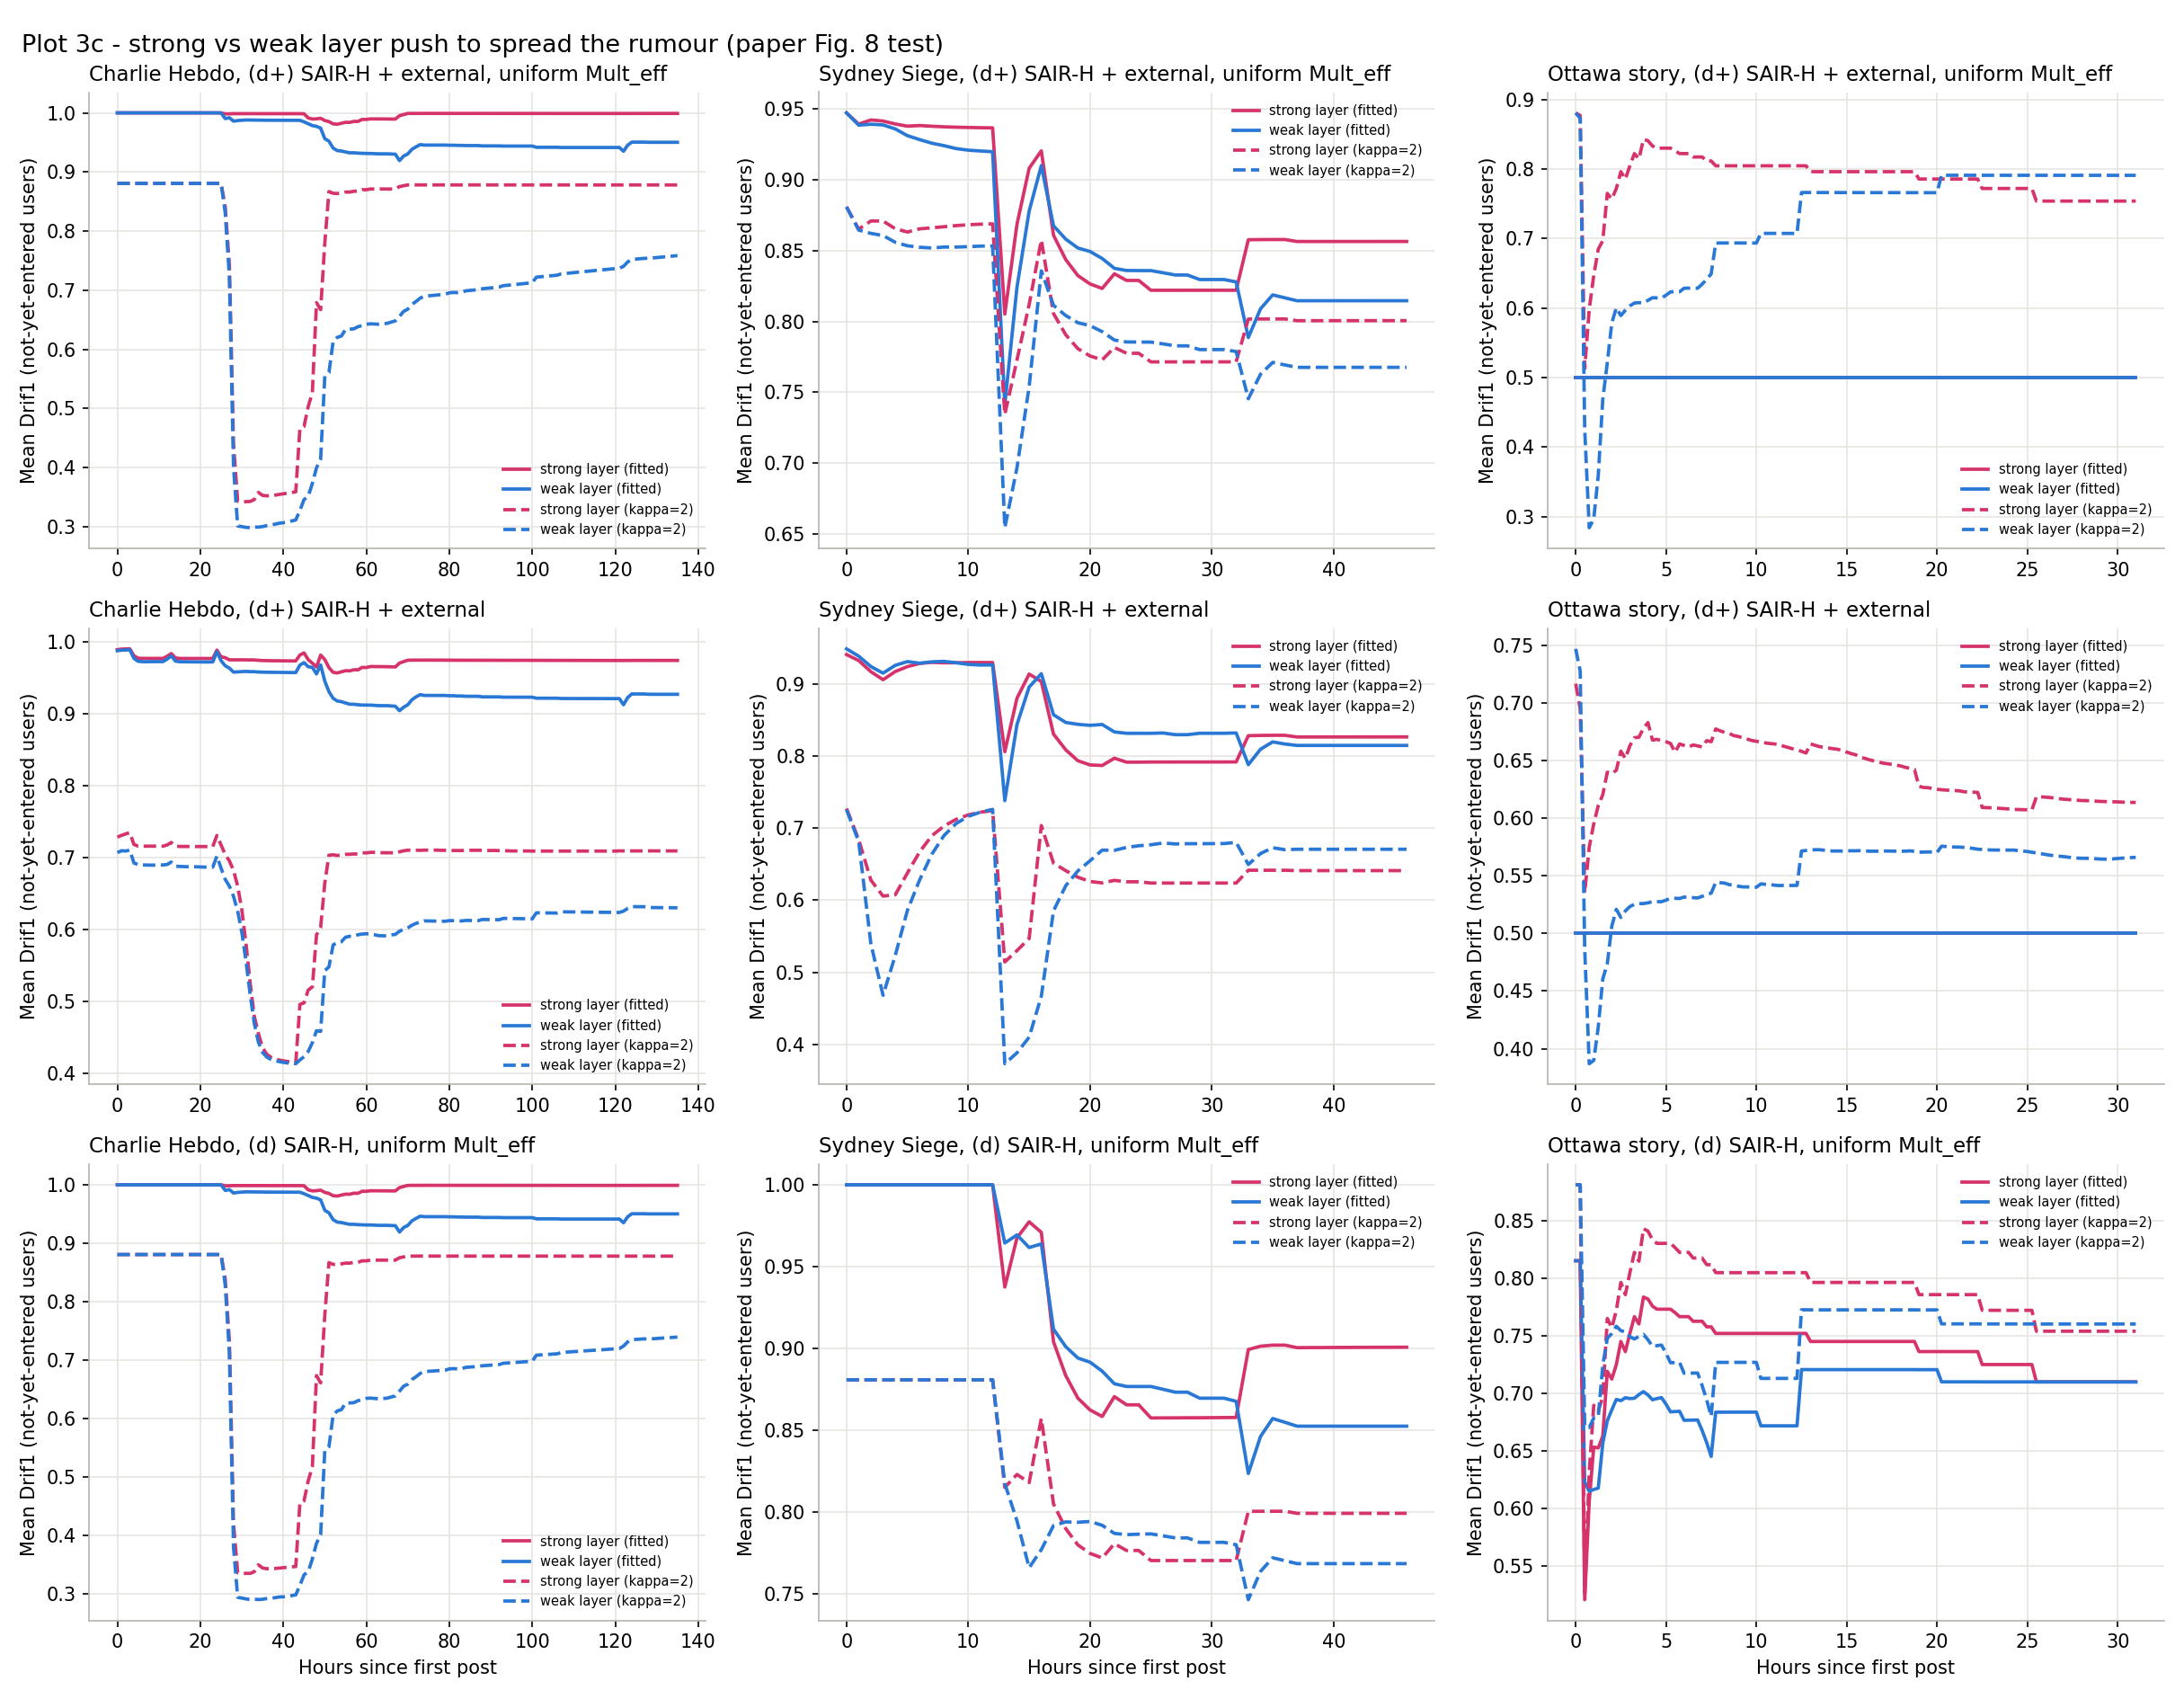

In [7]:
run('src/ablation.py --check')
show('phase6_plot3_knockouts.png', 'phase6_plot3b_importance.png', 'phase6_plot3_knockouts_paper.png', 'phase6_plot3b_importance_paper.png', 'phase6_plot3c_layers.png')

## Phase 7: SAIR-C control and tipping robustness

                                   hybrid             0.710  0.710         0.377  0.710          0.469  0.000
                                   refute             0.737  0.737         0.396  0.737          0.463  0.000

--- Phase 7 check ---
unit test (docs worked step): S=0.837 I=0.052 A=0.056 B=0.005 R=0.050 sum=1.000000  OK
charliehebdo           OK  lam=0 == Phase 5 run (max diff 2.8e-14; Phase 7 step vs Phase 5 step 0.0e+00)  max|sum-1|=3.6e-14  states in [0.0e+00, 0.999248]  dt vs dt/2 <= 2.7e-04 (D, peak rel. 2.8e-05)  numba == Python (0.0e+00)
sydneysiege            OK  lam=0 == Phase 5 run (max diff 7.1e-15; Phase 7 step vs Phase 5 step 4.9e-06)  max|sum-1|=1.7e-13  states in [0.0e+00, 1.000000]  dt vs dt/2 <= 5.2e-04 (D, peak rel. 1.4e-04)  numba == Python (0.0e+00)
story_three_shootings  OK  lam=0 == Phase 5 run (max diff 3.6e-15; Phase 7 step vs Phase 5 step 0.0e+00)  max|sum-1|=1.3e-13  states in [0.0e+00, 1.000000]  dt vs dt/2 <= 1.5e-04 (D, peak rel. 6.3e-04)  numba == 

      kappa50       7 0.0873 12.8427 0.0436 0.0548 50.0000 0.3173 0.0006    0.0      0.5810 -1658.4952       -0.7538              11.0           eta_I@low;eta_A@low
      fb_half       8 0.2140  0.1592 0.0494 0.0144  0.0893 0.2486 0.0000    0.0      0.8379 -1556.8740      100.8674               9.0 kappa@low;eta_I@low;eta_A@low
fb_half_fixed       8 0.0874 13.0125 0.0437 0.0554 12.4784 0.3179 0.0005    0.0 171748.6713  1769.8520     3427.5934               NaN           eta_I@low;eta_A@low
=== CH strategies at equal effort per variant: D/D0 (lam_u, lam_v), final C_A; tipped = D/D0 < 0.5 and C_A > 0.5 ===
--- E = 5% of N
main           (no-control C_A 0.019)  block: 0.934 (0.06, 0) C_A 0.02   refute: 0.930 (0, 0.0653) C_A 0.11   hybrid: 0.929 (0.0126, 0.0506) C_A 0.10
kappa5         (no-control C_A 0.019)  block: 0.934 (0.06, 0) C_A 0.02   refute: 0.071 (0, 0.878) C_A 0.94 TIPPED   hybrid: 0.065 (0.224, 0.447) C_A 0.93 TIPPED
kappa12.5      (no-control C_A 0.019)  block: 0.934 (0.06, 0)

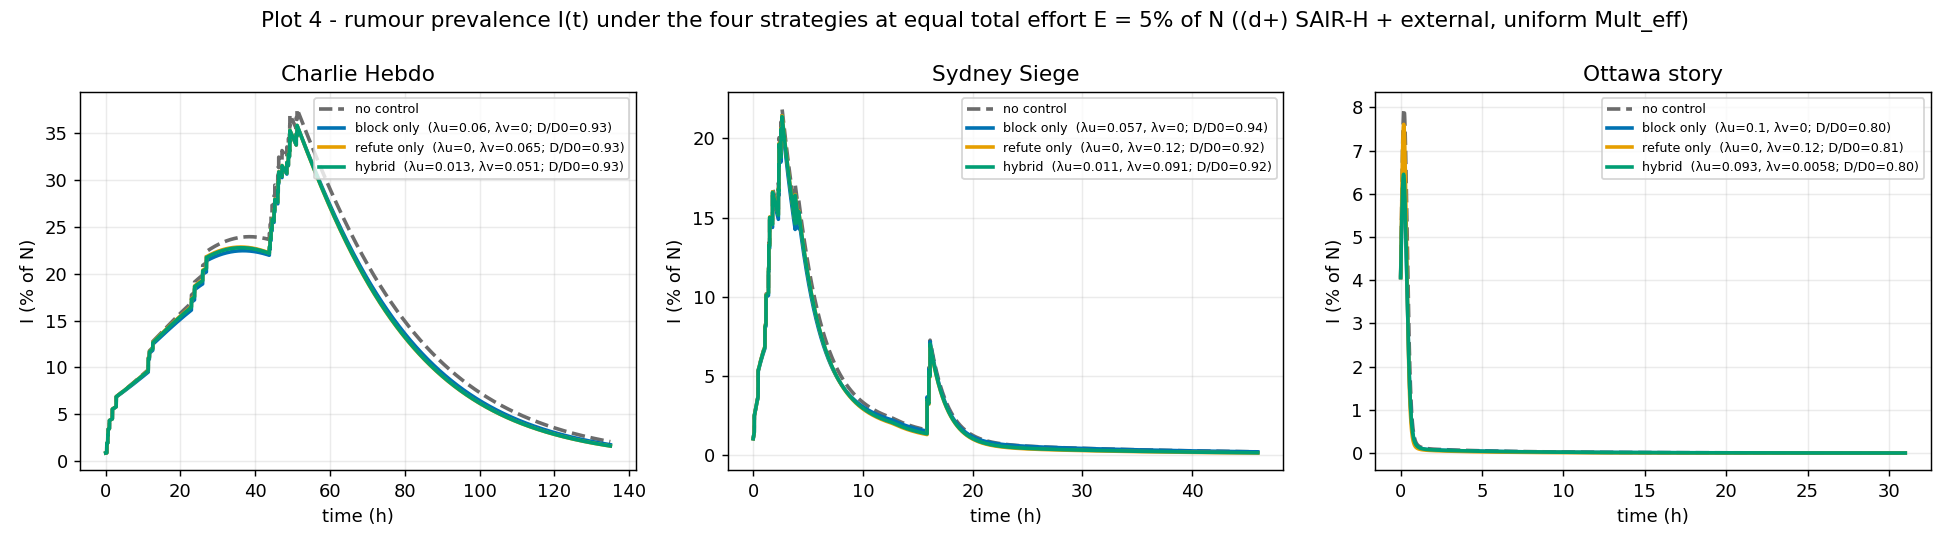

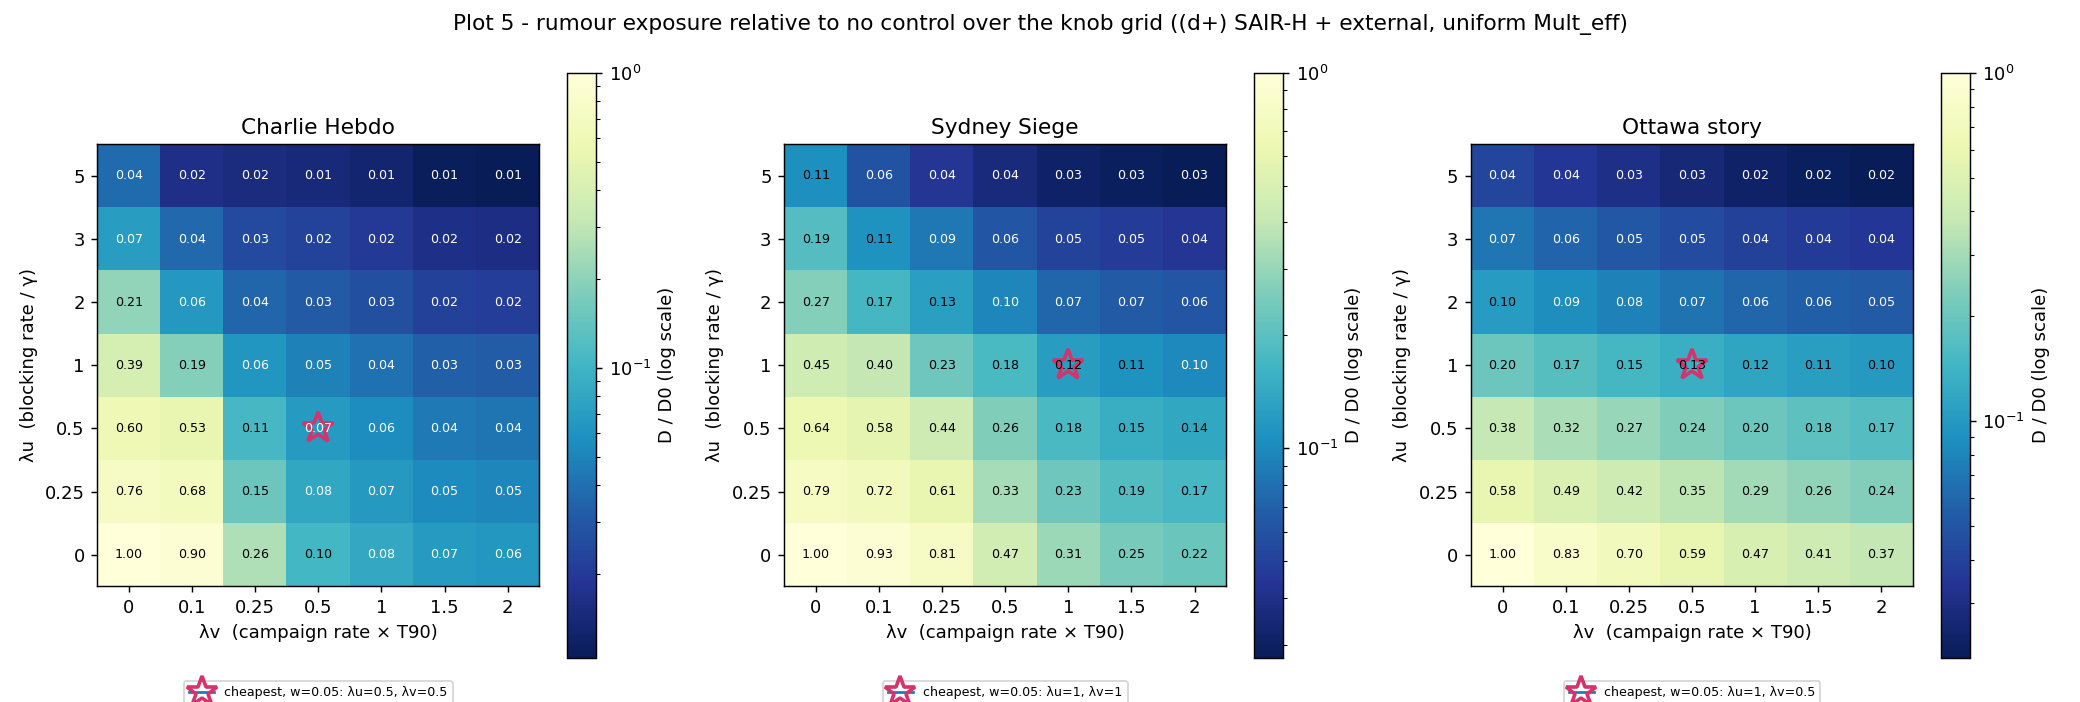

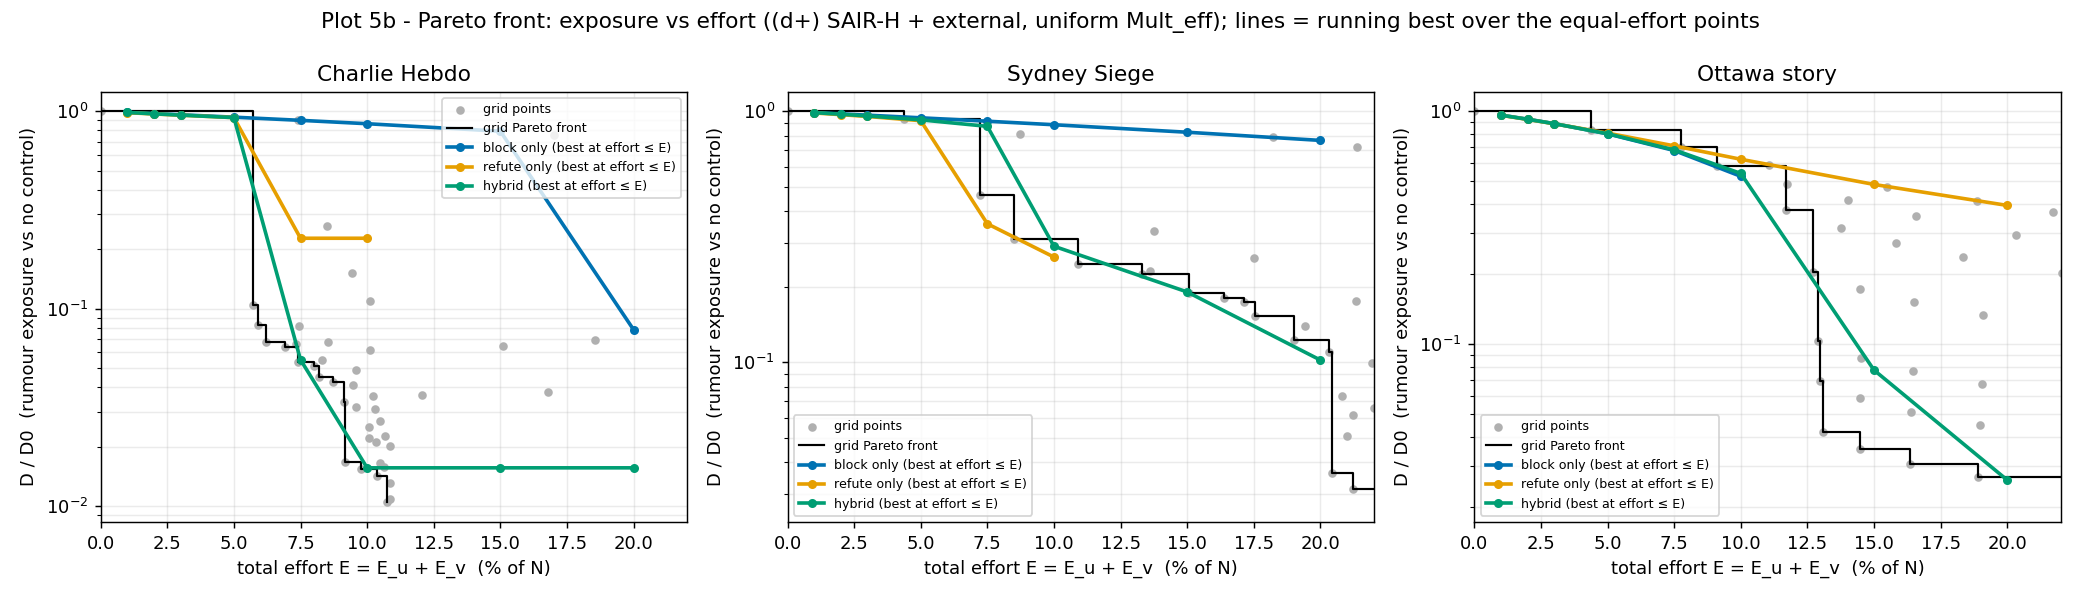

In [8]:
run('src/control.py --check')
run('src/control.py --tipping', tail=20)
show('phase7_plot4_strategies.png', 'phase7_plot5_heatmap.png', 'phase7_plot5b_pareto.png')

## Phase 8: targeting on PHEME and on Barabási–Albert networks

        0.010   1.275     1.319        1.291   1.109
        0.020   1.743     1.574        1.457   0.480
hybrid  0.001   0.081     0.081        0.081   0.099
        0.005   0.086     0.083        0.084   0.091
        0.010   0.090     0.091        0.088   0.085
        0.020   0.100     0.098        0.099   0.081
recruit 0.001   0.075     0.075        0.074   0.095
        0.005   0.070     0.071        0.070   0.085
        0.010   0.068     0.068        0.069   0.081
        0.020   0.066     0.066        0.067   0.077

--- Phase 8 check, part A (PHEME) ---
charliehebdo           OK  empty intervention == baseline == Phase 5 curves; same k for every method; targets in pools; max|sum-1|=1.9e-14; effort = blocked/N + injected A mass (s scales it exactly); source injections removed by block (k=100): degree 27, PageRank 27, betweenness 7
sydneysiege            OK  empty intervention == baseline == Phase 5 curves; same k for every method; targets in pools; max|sum-1|=7.9e-14; effort = 

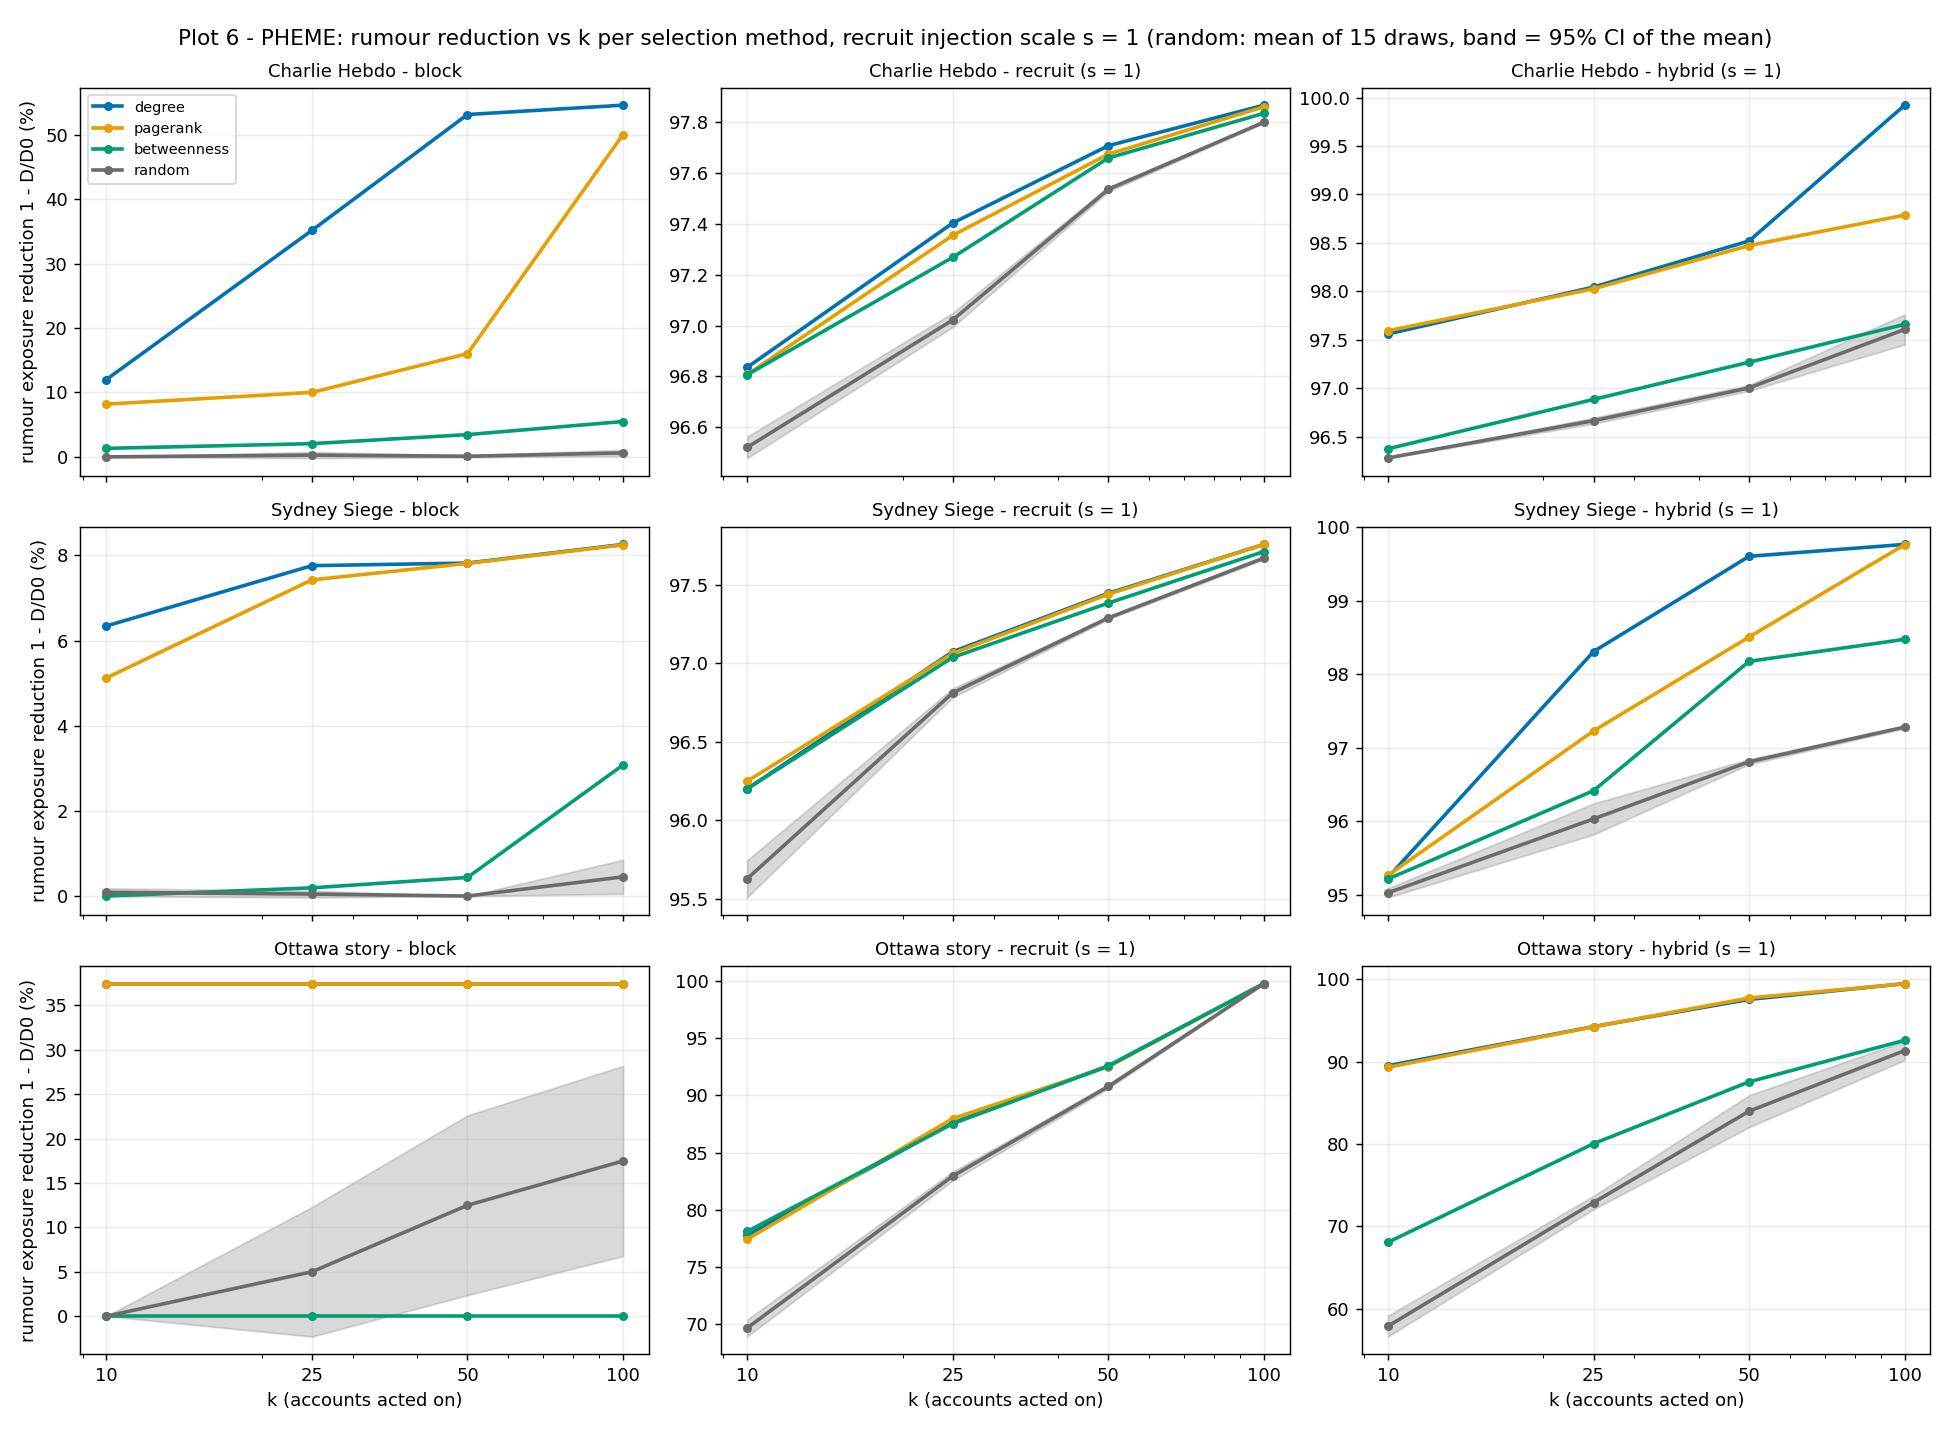

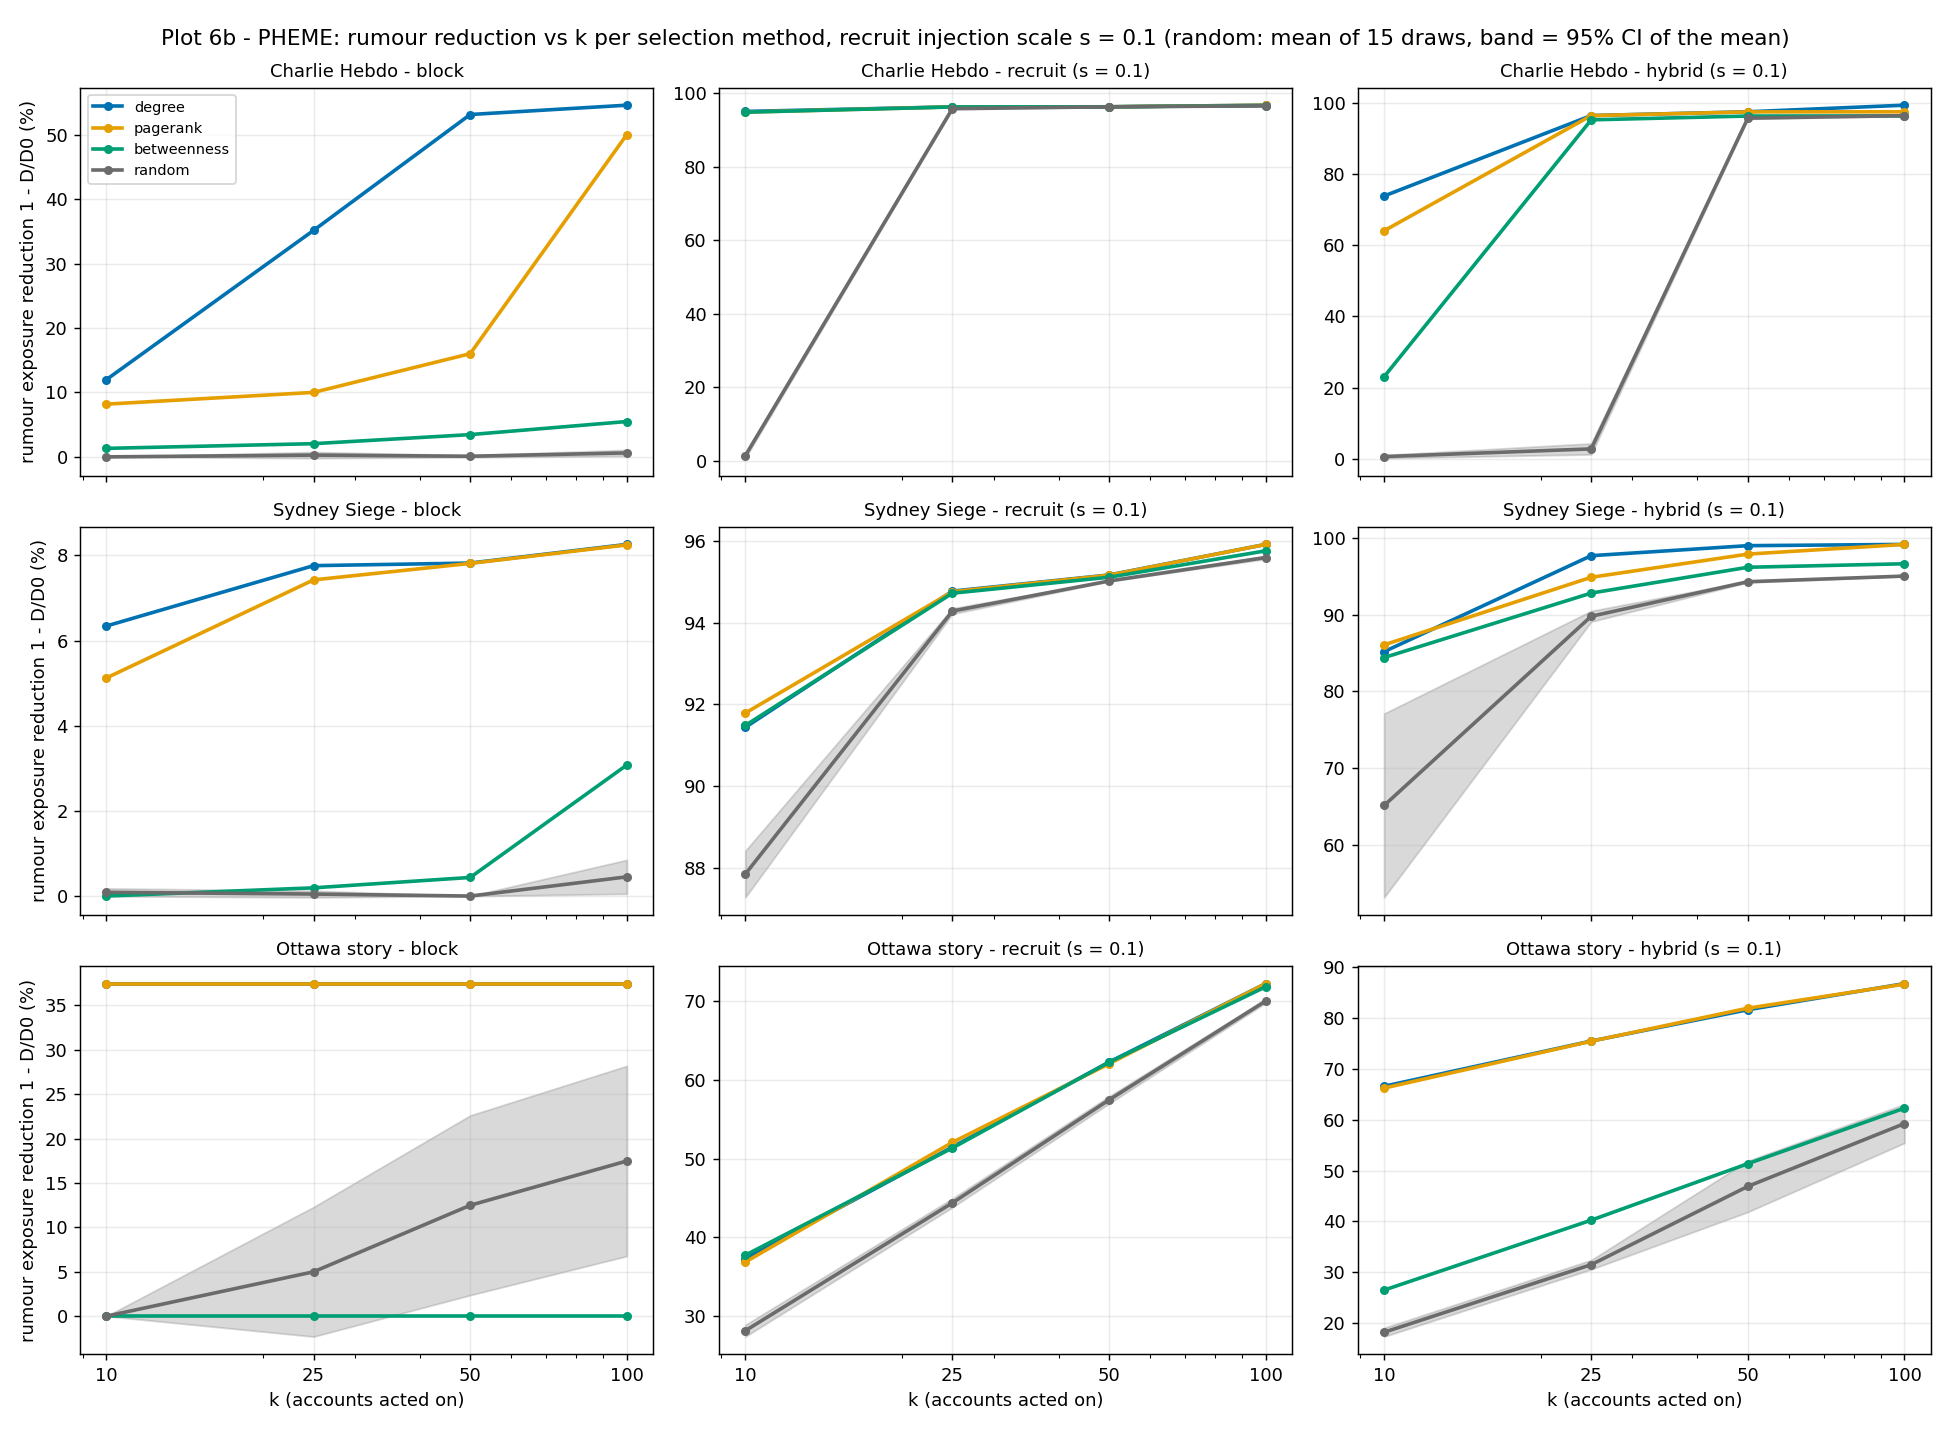

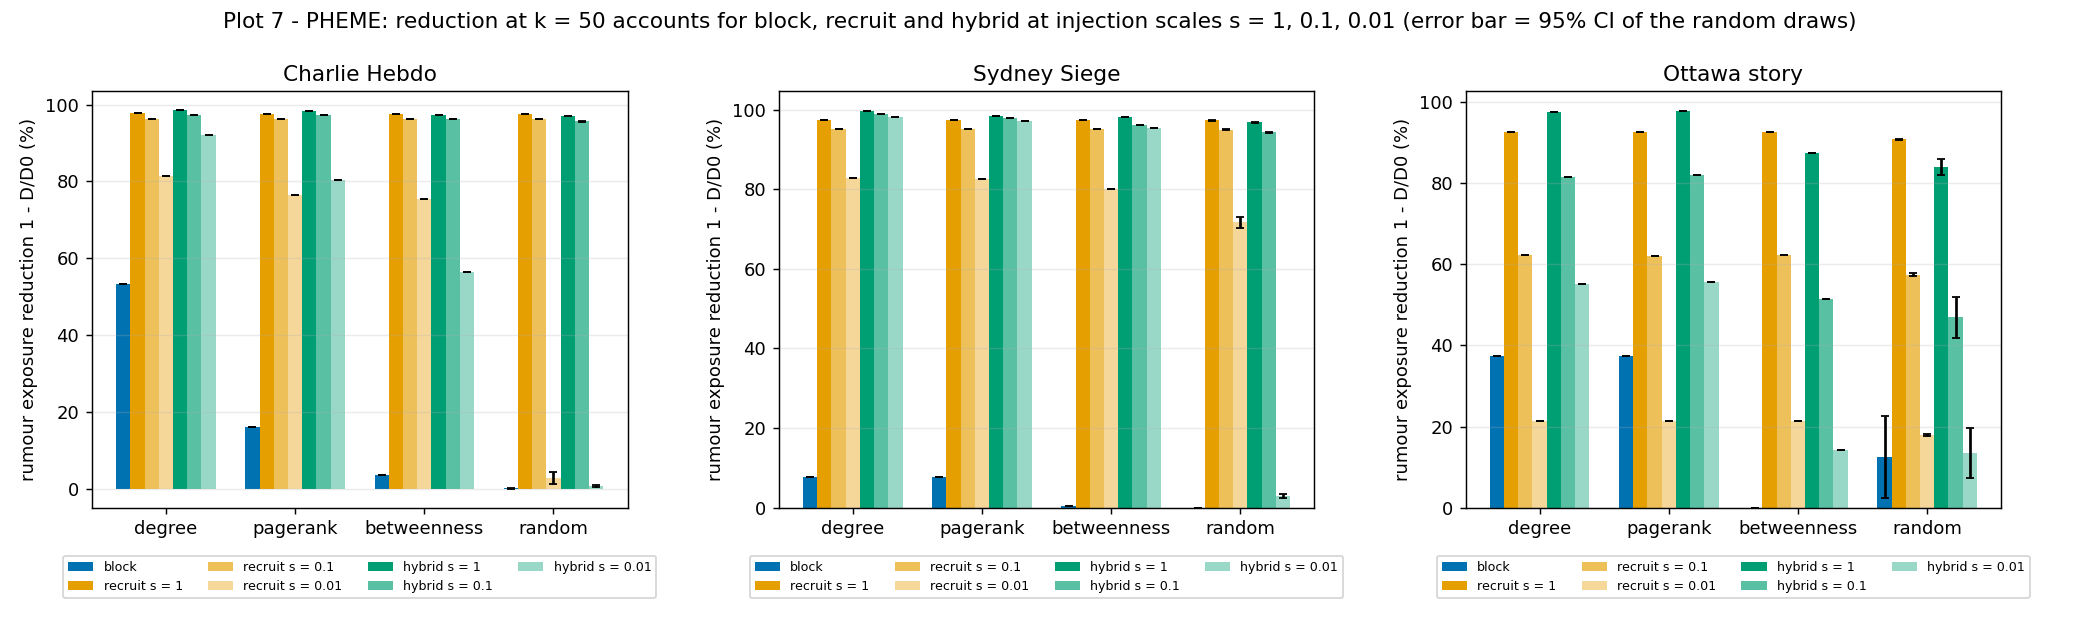

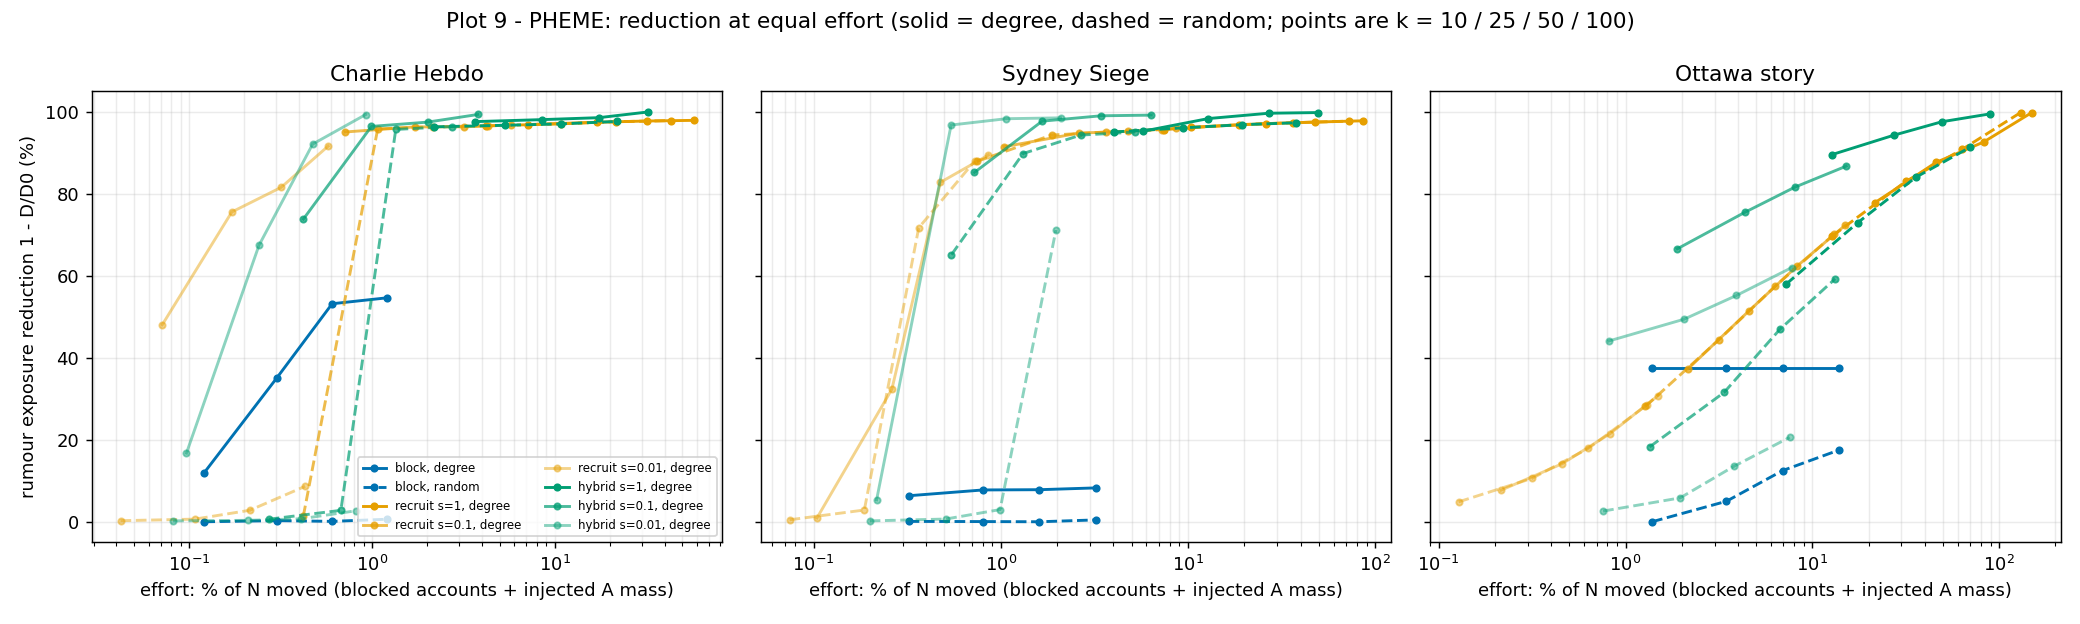

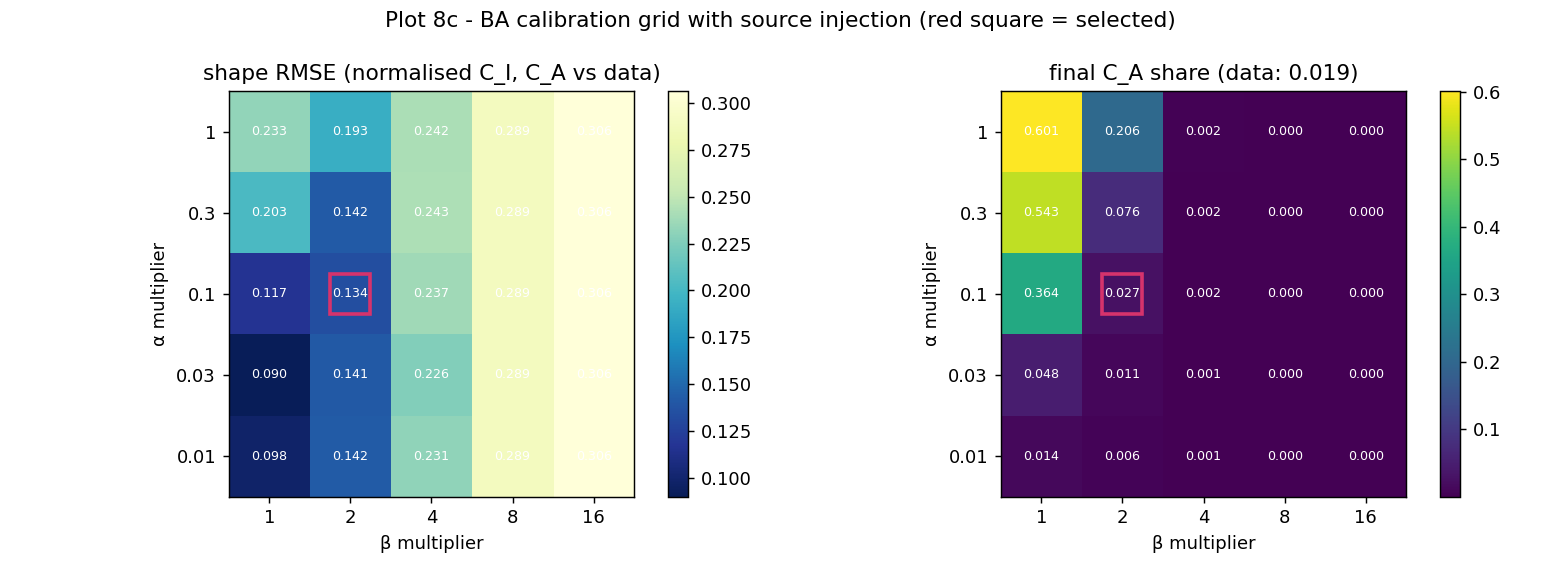

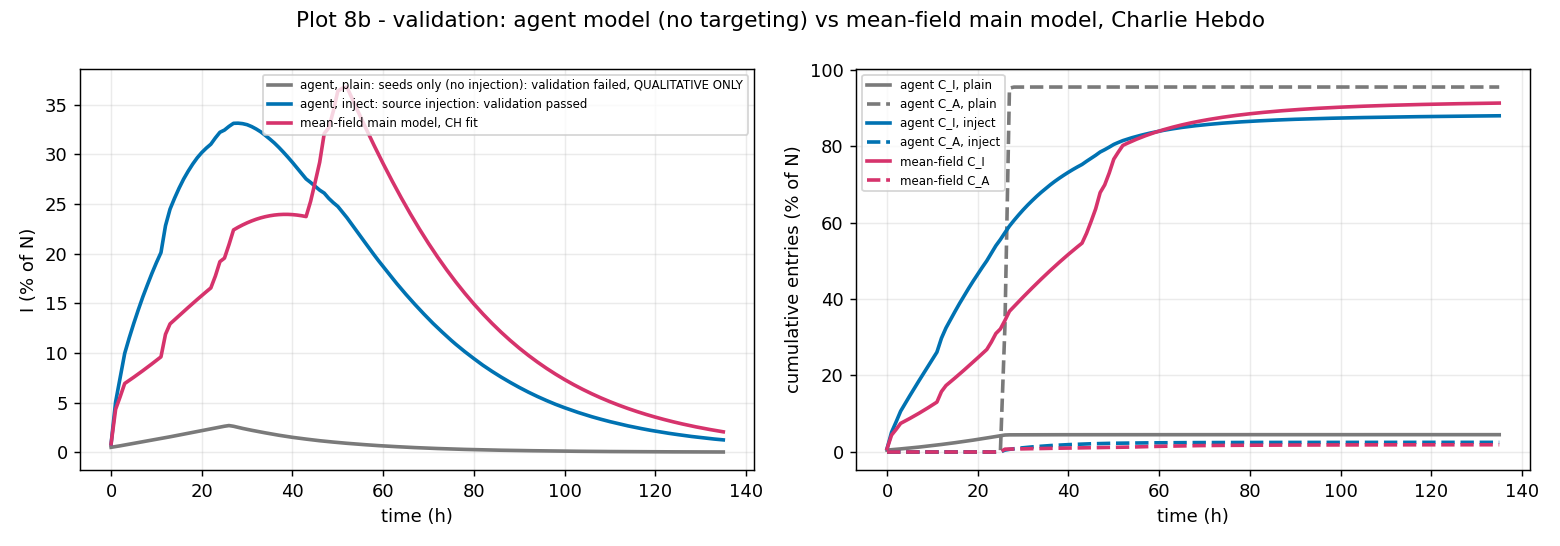

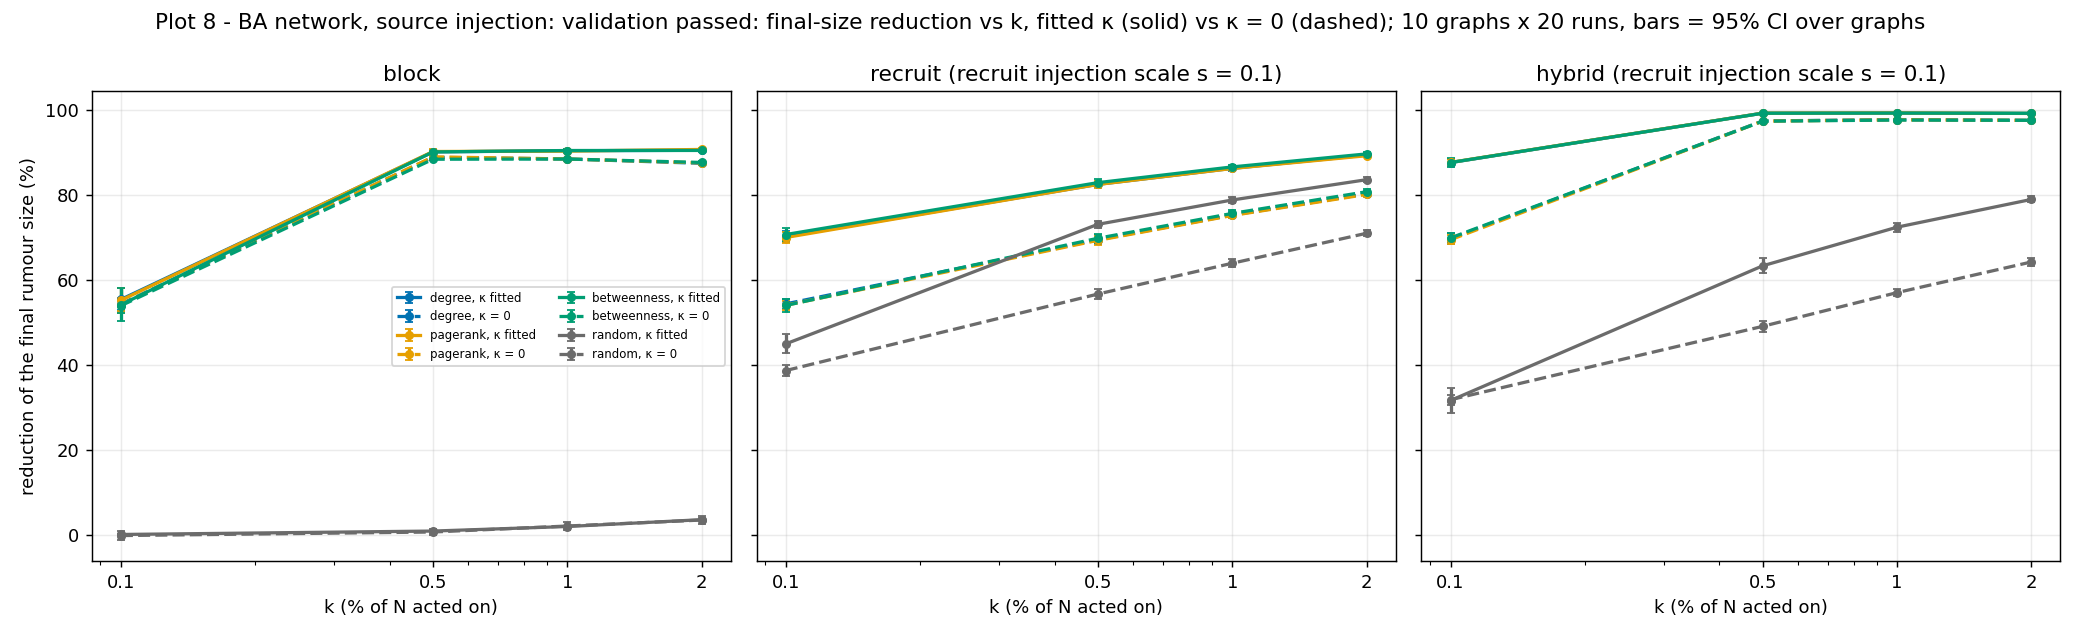

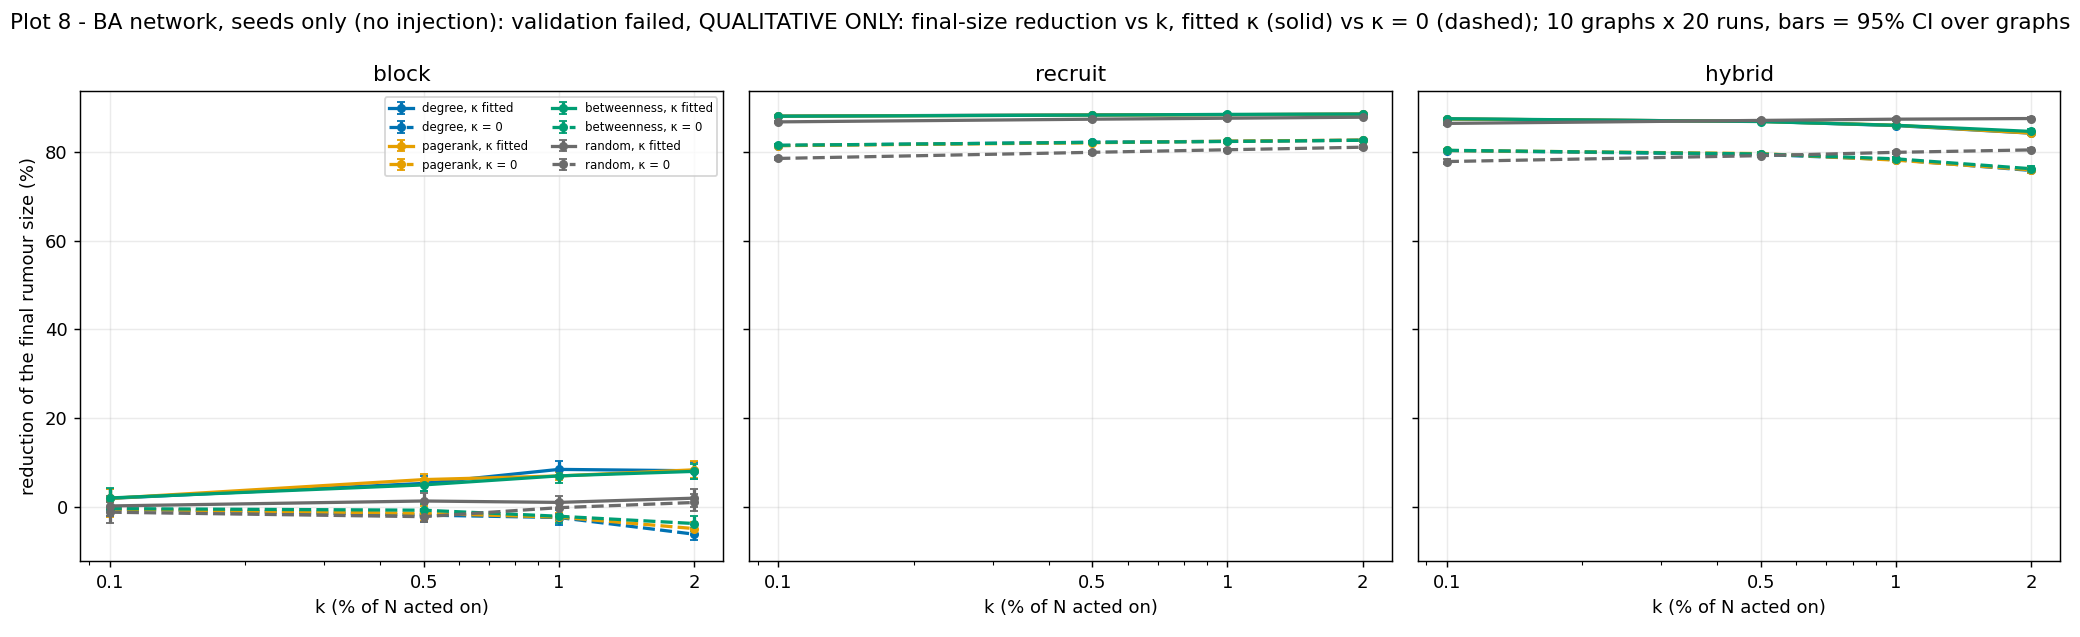

In [9]:
run('src/targeting.py --part AB --check', tail=20)
show('phase8_plot6_pheme_reduction.png', 'phase8_plot6b_pheme_reduction_s0.1.png', 'phase8_plot7_pheme_bars.png', 'phase8_plot9_effort.png',
     'phase8_plot8c_ba_calibration.png', 'phase8_plot8b_ba_validation.png', 'phase8_plot8_ba_reduction.png', 'phase8_plot8_ba_reduction_noinjection.png')

## Phase 9: report numbers

In [10]:
run('src/report_check.py')

tables: 28 blocks regenerated from the CSVs, 28 identical; tables not used in the report: none
prose claims: 61 / 61 found with their CSV value
decimal numbers in the prose: 101, of which 81 are covered by a claim; uncovered: 0.05, 0.25, 0.95, 1.5, 3.10, 4.0, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 5.1, 5.3, 5.5
Report number check passed.
--- src/report_check.py: exit 0, 1 s
